<a href="https://colab.research.google.com/github/gerald-hlabiso/SPS-Corps-2026--Gerald-Monica-Abubakar/blob/main/projects/fpa-financial-planning-variance-analytics/fpa-financial-planning-variance-analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Financial Planning, Forecasting & Variance Analytics

## FP&A Decision-Support System

This notebook develops a realistic financial-planning and analysis workflow for Summit Industrial Products, Inc., a fictional U.S. industrial-products company.

The project covers:

- Budget, Actual, and Forecast reporting
- Revenue price-volume-mix analysis
- COGS and gross-margin analysis
- Operating-expense variance analysis
- Rolling year-end forecasting
- General-ledger reconciliation
- Exception monitoring
- Management scenario analysis

### Technology Workflow

**SQL → Python → Excel → Power BI**

> All companies, customers, transactions, and financial results in this project are synthetic and created for educational and portfolio purposes.

In [1]:
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

print("FP&A project environment initialized successfully.")

FP&A project environment initialized successfully.


## 1. Company Configuration and Dimension Tables

This section defines the reporting period, business units, regions, products, customer segments, departments, and financial scenarios used throughout the project.

In [2]:
# Reporting period
START_DATE = "2024-01-01"
END_DATE = "2026-12-31"

# Date dimension
dates = pd.date_range(START_DATE, END_DATE, freq="D")

dim_date = pd.DataFrame({
    "date_id": dates.strftime("%Y%m%d").astype(int),
    "full_date": dates
})

dim_date["day"] = dim_date["full_date"].dt.day
dim_date["month"] = dim_date["full_date"].dt.month
dim_date["month_name"] = dim_date["full_date"].dt.month_name()
dim_date["quarter"] = "Q" + dim_date["full_date"].dt.quarter.astype(str)
dim_date["year"] = dim_date["full_date"].dt.year
dim_date["year_month"] = dim_date["full_date"].dt.to_period("M").astype(str)

# Business-unit dimension
dim_business_unit = pd.DataFrame({
    "business_unit_id": ["BU01", "BU02", "BU03", "BU04"],
    "business_unit_name": [
        "Industrial Components",
        "Automation Equipment",
        "Maintenance Supplies",
        "Custom Solutions"
    ],
    "manager_name": [
        "Jordan Miller",
        "Taylor Brooks",
        "Morgan Reed",
        "Casey Bennett"
    ],
    "status": ["Active"] * 4
})

# Region dimension
dim_region = pd.DataFrame({
    "region_id": ["R01", "R02", "R03", "R04"],
    "region_name": ["Midwest", "Northeast", "South", "West"],
    "regional_weight": [0.32, 0.23, 0.27, 0.18]
})

# Customer-segment dimension
dim_customer_segment = pd.DataFrame({
    "customer_segment_id": ["CS01", "CS02", "CS03"],
    "customer_segment": [
        "Small Business",
        "Mid-Market",
        "Enterprise"
    ],
    "segment_weight": [0.30, 0.45, 0.25],
    "typical_discount_rate": [0.00, 0.04, 0.08]
})

# Department dimension
dim_department = pd.DataFrame({
    "department_id": ["D01", "D02", "D03", "D04", "D05", "D06"],
    "department_name": [
        "Sales",
        "Operations",
        "Finance",
        "Technology",
        "Marketing",
        "Administration"
    ]
})

# Scenario dimension
dim_scenario = pd.DataFrame({
    "scenario_id": ["S01", "S02", "S03", "S04"],
    "scenario_name": [
        "Original Budget",
        "Previous Forecast",
        "Current Forecast",
        "Actual"
    ],
    "scenario_order": [1, 2, 3, 4]
})

# Product dimension
product_records = [
    ["P001", "Precision Bearings", "Mechanical Components", "BU01", 180.00, 108.00],
    ["P002", "Industrial Fasteners", "Mechanical Components", "BU01", 75.00, 42.00],
    ["P003", "Hydraulic Assemblies", "Mechanical Components", "BU01", 420.00, 260.00],

    ["P004", "Control Panel System", "Automation Systems", "BU02", 1850.00, 1190.00],
    ["P005", "Industrial Sensor Kit", "Automation Systems", "BU02", 680.00, 405.00],
    ["P006", "Robotic Interface Module", "Automation Systems", "BU02", 2400.00, 1580.00],

    ["P007", "Preventive Maintenance Kit", "Maintenance Products", "BU03", 310.00, 175.00],
    ["P008", "Industrial Lubricant Pack", "Maintenance Products", "BU03", 95.00, 48.00],
    ["P009", "Safety Equipment Bundle", "Maintenance Products", "BU03", 260.00, 145.00],

    ["P010", "Process Optimization Study", "Professional Services", "BU04", 8500.00, 4600.00],
    ["P011", "Custom System Integration", "Professional Services", "BU04", 15000.00, 8700.00],
    ["P012", "Technical Training Program", "Professional Services", "BU04", 5200.00, 2750.00]
]

dim_product = pd.DataFrame(
    product_records,
    columns=[
        "product_id",
        "product_name",
        "product_category",
        "business_unit_id",
        "standard_price",
        "standard_unit_cost"
    ]
)

dim_product["standard_unit_margin"] = (
    dim_product["standard_price"] -
    dim_product["standard_unit_cost"]
)

dim_product["standard_margin_pct"] = (
    dim_product["standard_unit_margin"] /
    dim_product["standard_price"]
)

print("Dimension tables created successfully.")
print(f"Date records: {len(dim_date):,}")
print(f"Business units: {len(dim_business_unit)}")
print(f"Regions: {len(dim_region)}")
print(f"Customer segments: {len(dim_customer_segment)}")
print(f"Departments: {len(dim_department)}")
print(f"Scenarios: {len(dim_scenario)}")
print(f"Products: {len(dim_product)}")

dim_product

Dimension tables created successfully.
Date records: 1,096
Business units: 4
Regions: 4
Customer segments: 3
Departments: 6
Scenarios: 4
Products: 12


,product_id,product_name,product_category,business_unit_id,standard_price,standard_unit_cost,standard_unit_margin,standard_margin_pct
0,P001,Precision Bearings,Mechanical Components,BU01,180.00,108.00,72.00,0.40
1,P002,Industrial Fasteners,Mechanical Components,BU01,75.00,42.00,33.00,0.44
2,P003,Hydraulic Assemblies,Mechanical Components,BU01,420.00,260.00,160.00,0.38
3,P004,Control Panel System,Automation Systems,BU02,"1,850.00","1,190.00",660.00,0.36
4,P005,Industrial Sensor Kit,Automation Systems,BU02,680.00,405.00,275.00,0.40
5,P006,Robotic Interface Module,Automation Systems,BU02,"2,400.00","1,580.00",820.00,0.34
6,P007,Preventive Maintenance Kit,Maintenance Products,BU03,310.00,175.00,135.00,0.44
7,P008,Industrial Lubricant Pack,Maintenance Products,BU03,95.00,48.00,47.00,0.49
8,P009,Safety Equipment Bundle,Maintenance Products,BU03,260.00,145.00,115.00,0.44
9,P010,Process Optimization Study,Professional Services,BU04,"8,500.00","4,600.00","3,900.00",0.46


## 2. Customer and Financial Account Dimensions

This section creates synthetic customers and the chart of accounts used for financial reporting.

In [3]:
# -----------------------------
# Customer dimension
# -----------------------------

CUSTOMER_COUNT = 240

industries = [
    "Manufacturing",
    "Construction",
    "Transportation",
    "Healthcare",
    "Energy",
    "Retail",
    "Technology",
    "Government"
]

segment_probabilities = (
    dim_customer_segment
    .set_index("customer_segment_id")["segment_weight"]
    .to_dict()
)

region_probabilities = (
    dim_region
    .set_index("region_id")["regional_weight"]
    .to_dict()
)

customer_segment_ids = rng.choice(
    list(segment_probabilities.keys()),
    size=CUSTOMER_COUNT,
    p=list(segment_probabilities.values())
)

customer_region_ids = rng.choice(
    list(region_probabilities.keys()),
    size=CUSTOMER_COUNT,
    p=list(region_probabilities.values())
)

segment_discount_map = (
    dim_customer_segment
    .set_index("customer_segment_id")["typical_discount_rate"]
    .to_dict()
)

segment_demand_map = {
    "CS01": 0.70,   # Small Business
    "CS02": 1.20,   # Mid-Market
    "CS03": 2.10    # Enterprise
}

dim_customer = pd.DataFrame({
    "customer_id": [
        f"C{i:04d}" for i in range(1, CUSTOMER_COUNT + 1)
    ],
    "customer_name": [
        f"Summit Customer {i:04d}"
        for i in range(1, CUSTOMER_COUNT + 1)
    ],
    "customer_segment_id": customer_segment_ids,
    "region_id": customer_region_ids,
    "industry": rng.choice(
        industries,
        size=CUSTOMER_COUNT
    )
})

dim_customer["base_discount_rate"] = (
    dim_customer["customer_segment_id"]
    .map(segment_discount_map)
)

dim_customer["base_demand_factor"] = (
    dim_customer["customer_segment_id"]
    .map(segment_demand_map)
    * rng.uniform(0.80, 1.20, size=CUSTOMER_COUNT)
)

dim_customer["active_status"] = rng.choice(
    ["Active", "Inactive"],
    size=CUSTOMER_COUNT,
    p=[0.96, 0.04]
)

# -----------------------------
# Chart of accounts
# -----------------------------

account_records = [
    ["A4000", "4000", "Product Revenue", "Revenue", "Product Revenue"],
    ["A4010", "4010", "Service Revenue", "Revenue", "Service Revenue"],
    ["A4020", "4020", "Custom Solutions Revenue", "Revenue", "Service Revenue"],
    ["A4090", "4090", "Sales Returns and Discounts", "Revenue", "Contra Revenue"],

    ["A5000", "5000", "Direct Materials", "COGS", "Materials"],
    ["A5010", "5010", "Direct Labor", "COGS", "Labor"],
    ["A5020", "5020", "Manufacturing Overhead", "COGS", "Manufacturing"],
    ["A5030", "5030", "Freight and Distribution", "COGS", "Distribution"],
    ["A5040", "5040", "Inventory Adjustments", "COGS", "Inventory"],

    ["A6000", "6000", "Salaries and Benefits", "OPEX", "Labor"],
    ["A6010", "6010", "Marketing and Advertising", "OPEX", "Marketing"],
    ["A6020", "6020", "Technology and Software", "OPEX", "Technology"],
    ["A6030", "6030", "Logistics", "OPEX", "Logistics"],
    ["A6040", "6040", "Facilities and Utilities", "OPEX", "Facilities"],
    ["A6050", "6050", "Professional Services", "OPEX", "Professional Services"],
    ["A6060", "6060", "Travel and Entertainment", "OPEX", "Travel"],
    ["A6070", "6070", "Depreciation and Amortization", "OPEX", "Depreciation"],
    ["A6080", "6080", "Other Administrative Expenses", "OPEX", "Administration"]
]

dim_account = pd.DataFrame(
    account_records,
    columns=[
        "account_id",
        "account_code",
        "account_name",
        "account_category",
        "account_subcategory"
    ]
)

# Validation summaries
print("Customer and account dimensions created successfully.")
print(f"Customers: {len(dim_customer):,}")
print(f"Accounts: {len(dim_account)}")

print("\nCustomers by segment:")
display(
    dim_customer
    .merge(
        dim_customer_segment[
            ["customer_segment_id", "customer_segment"]
        ],
        on="customer_segment_id",
        how="left"
    )
    ["customer_segment"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customer_count")
)

print("\nAccounts by category:")
display(
    dim_account["account_category"]
    .value_counts()
    .rename_axis("account_category")
    .reset_index(name="account_count")
)

dim_customer.head()

Customer and account dimensions created successfully.
Customers: 240
Accounts: 18

Customers by segment:


,customer_segment,customer_count
0,Mid-Market,107
1,Small Business,74
2,Enterprise,59



Accounts by category:


,account_category,account_count
0,OPEX,9
1,COGS,5
2,Revenue,4


,customer_id,customer_name,customer_segment_id,region_id,industry,base_discount_rate,base_demand_factor,active_status
0,C0001,Summit Customer 0001,CS03,R04,Construction,0.08,2.08,Active
1,C0002,Summit Customer 0002,CS02,R03,Healthcare,0.04,1.33,Active
2,C0003,Summit Customer 0003,CS03,R01,Technology,0.08,2.44,Active
3,C0004,Summit Customer 0004,CS02,R02,Construction,0.04,1.31,Active
4,C0005,Summit Customer 0005,CS01,R03,Government,0.00,0.83,Active


## 3. External Economic Data

This project combines synthetic company-level financial records with official monthly U.S. economic indicators retrieved through the Federal Reserve Bank of St. Louis FRED service.

### External drivers

- Manufacturing production
- Core capital-goods orders
- Industrial commodity prices
- Freight transportation activity

In [4]:
# -----------------------------
# Download official FRED data
# -----------------------------

fred_series = {
    "IPMAN": "manufacturing_index",
    "NEWORDER": "new_orders_millions",
    "PPIIDC": "industrial_ppi",
    "TSIFRGHT": "freight_index"
}

def load_fred_series(series_id, value_name):
    """
    Download one monthly economic series from FRED.
    """
    url = (
        "https://fred.stlouisfed.org/graph/"
        f"fredgraph.csv?id={series_id}"
    )

    data = pd.read_csv(url)

    # FRED may label the date column DATE or observation_date
    date_column = data.columns[0]

    data = data.rename(
        columns={
            date_column: "month_date",
            series_id: value_name
        }
    )

    data["month_date"] = pd.to_datetime(
        data["month_date"],
        errors="coerce"
    )

    data[value_name] = pd.to_numeric(
        data[value_name],
        errors="coerce"
    )

    data = data[
        ["month_date", value_name]
    ].dropna(subset=["month_date"])

    return data


macro_data_raw = None
latest_observations = []

for series_id, value_name in fred_series.items():

    series_data = load_fred_series(
        series_id,
        value_name
    )

    latest_valid_date = series_data.loc[
        series_data[value_name].notna(),
        "month_date"
    ].max()

    latest_observations.append({
        "series_id": series_id,
        "variable": value_name,
        "latest_observation": latest_valid_date
    })

    if macro_data_raw is None:
        macro_data_raw = series_data
    else:
        macro_data_raw = macro_data_raw.merge(
            series_data,
            on="month_date",
            how="outer"
        )


# Keep the reporting period
macro_data_raw = (
    macro_data_raw[
        (macro_data_raw["month_date"] >= START_DATE)
        & (macro_data_raw["month_date"] <= END_DATE)
    ]
    .sort_values("month_date")
    .reset_index(drop=True)
)


# Complete monthly calendar through December 2026
monthly_calendar = pd.DataFrame({
    "month_date": pd.date_range(
        START_DATE,
        END_DATE,
        freq="MS"
    )
})

macro_data = monthly_calendar.merge(
    macro_data_raw,
    on="month_date",
    how="left"
)

macro_data["year"] = macro_data["month_date"].dt.year
macro_data["month"] = macro_data["month_date"].dt.month
macro_data["quarter"] = (
    "Q"
    + macro_data["month_date"]
    .dt.quarter
    .astype(str)
)

macro_data["year_month"] = (
    macro_data["month_date"]
    .dt.to_period("M")
    .astype(str)
)


# Show whether each month contains all four observations
economic_columns = list(fred_series.values())

macro_data["available_indicator_count"] = (
    macro_data[economic_columns]
    .notna()
    .sum(axis=1)
)

macro_data["data_status"] = np.select(
    [
        macro_data["available_indicator_count"].eq(4),
        macro_data["available_indicator_count"].between(
            1, 3
        )
    ],
    [
        "All Indicators Observed",
        "Partially Observed"
    ],
    default="Projection Required"
)


latest_observations = pd.DataFrame(
    latest_observations
)

print("Official economic data downloaded successfully.")

print("\nLatest observation available for each series:")
display(latest_observations)

print("\nMonthly economic dataset:")
display(macro_data.tail(12))

print("\nData-status summary:")
display(
    macro_data["data_status"]
    .value_counts()
    .rename_axis("data_status")
    .reset_index(name="months")
)

Official economic data downloaded successfully.

Latest observation available for each series:


,series_id,variable,latest_observation
0,IPMAN,manufacturing_index,2026-08-01
1,NEWORDER,new_orders_millions,2026-08-01
2,PPIIDC,industrial_ppi,2026-08-01
3,TSIFRGHT,freight_index,2026-07-01



Monthly economic dataset:


,month_date,manufacturing_index,new_orders_millions,industrial_ppi,freight_index,year,month,quarter,year_month,available_indicator_count,data_status
24,2026-01-01,97.08,"78,990.00",264.61,136.30,2026,1,Q1,2026-01,4,All Indicators Observed
25,2026-02-01,97.73,"80,235.00",270.19,138.40,2026,2,Q1,2026-02,4,All Indicators Observed
26,2026-03-01,98.09,"83,296.00",278.15,139.30,2026,3,Q1,2026-03,4,All Indicators Observed
27,2026-04-01,98.86,"82,778.00",285.90,138.20,2026,4,Q2,2026-04,4,All Indicators Observed
28,2026-05-01,98.98,"84,360.00",294.38,135.30,2026,5,Q2,2026-05,4,All Indicators Observed
29,2026-06-01,99.24,"85,757.00",289.68,136.60,2026,6,Q2,2026-06,4,All Indicators Observed
30,2026-07-01,99.40,"86,295.00",289.19,135.70,2026,7,Q3,2026-07,4,All Indicators Observed
31,2026-08-01,99.10,"87,640.00",293.21,NaN,2026,8,Q3,2026-08,3,Partially Observed
32,2026-09-01,NaN,NaN,NaN,NaN,2026,9,Q3,2026-09,0,Projection Required
33,2026-10-01,NaN,NaN,NaN,NaN,2026,10,Q4,2026-10,0,Projection Required



Data-status summary:


,data_status,months
0,All Indicators Observed,31
1,Projection Required,4
2,Partially Observed,1


## 4. Economic-Driver Projections

Official observations are retained unchanged. Missing future months are estimated using Holt-Winters time-series models so the FP&A system can produce a complete year-end forecast.

Projected values are clearly labeled and must not be interpreted as official government forecasts.

In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

macro_data_hybrid = macro_data.copy()

# Preserve the original downloaded observations
for column in economic_columns:
    macro_data_hybrid[f"{column}_observed"] = (
        macro_data_hybrid[column]
    )

projection_summary = []

for column in economic_columns:

    observed = (
        macro_data_hybrid[
            ["month_date", column]
        ]
        .dropna()
        .sort_values("month_date")
        .copy()
    )

    last_observed_date = observed["month_date"].max()

    future_mask = (
        macro_data_hybrid["month_date"]
        > last_observed_date
    )

    forecast_steps = int(future_mask.sum())

    if forecast_steps > 0:

        model = ExponentialSmoothing(
            observed[column],
            trend="add",
            seasonal="add",
            seasonal_periods=12,
            initialization_method="estimated"
        )

        fitted_model = model.fit(
            optimized=True
        )

        projected_values = fitted_model.forecast(
            forecast_steps
        ).to_numpy()

        macro_data_hybrid.loc[
            future_mask,
            column
        ] = projected_values

    macro_data_hybrid[f"{column}_source"] = np.where(
        macro_data_hybrid["month_date"]
        <= last_observed_date,
        "Observed",
        "Projected"
    )

    projection_summary.append({
        "variable": column,
        "last_observed_date": last_observed_date,
        "projected_months": forecast_steps
    })


projection_summary = pd.DataFrame(
    projection_summary
)

# Overall source classification
source_columns = [
    f"{column}_source"
    for column in economic_columns
]

observed_count = (
    macro_data_hybrid[source_columns]
    .eq("Observed")
    .sum(axis=1)
)

macro_data_hybrid["month_source"] = np.select(
    [
        observed_count.eq(len(economic_columns)),
        observed_count.between(
            1,
            len(economic_columns) - 1
        )
    ],
    [
        "Observed",
        "Mixed Observed and Projected"
    ],
    default="Projected"
)

# Calculate monthly and annual changes
for column in economic_columns:

    macro_data_hybrid[f"{column}_mom_change"] = (
        macro_data_hybrid[column]
        .pct_change(fill_method=None)
    )

    macro_data_hybrid[f"{column}_yoy_change"] = (
        macro_data_hybrid[column]
        .pct_change(
            periods=12,
            fill_method=None
        )
    )

# Normalize all drivers to January 2024 = 100
for column in economic_columns:

    baseline_value = (
        macro_data_hybrid.loc[
            macro_data_hybrid["month_date"]
            == pd.Timestamp("2024-01-01"),
            column
        ]
        .iloc[0]
    )

    macro_data_hybrid[f"{column}_normalized"] = (
        macro_data_hybrid[column]
        / baseline_value
        * 100
    )

# Validation
assert (
    macro_data_hybrid[economic_columns]
    .isna()
    .sum()
    .sum()
    == 0
)

print("Economic-driver projections completed successfully.")

print("\nProjection summary:")
display(projection_summary)

print("\nObserved and projected monthly drivers:")
display(
    macro_data_hybrid[
        [
            "month_date",
            "manufacturing_index",
            "new_orders_millions",
            "industrial_ppi",
            "freight_index",
            "month_source"
        ]
    ].tail(12)
)

print("\nMonth-source summary:")
display(
    macro_data_hybrid["month_source"]
    .value_counts()
    .rename_axis("month_source")
    .reset_index(name="months")
)

Economic-driver projections completed successfully.

Projection summary:


,variable,last_observed_date,projected_months
0,manufacturing_index,2026-08-01,4
1,new_orders_millions,2026-08-01,4
2,industrial_ppi,2026-08-01,4
3,freight_index,2026-07-01,5



Observed and projected monthly drivers:


,month_date,manufacturing_index,new_orders_millions,industrial_ppi,freight_index,month_source
24,2026-01-01,97.08,"78,990.00",264.61,136.30,Observed
25,2026-02-01,97.73,"80,235.00",270.19,138.40,Observed
26,2026-03-01,98.09,"83,296.00",278.15,139.30,Observed
27,2026-04-01,98.86,"82,778.00",285.90,138.20,Observed
28,2026-05-01,98.98,"84,360.00",294.38,135.30,Observed
29,2026-06-01,99.24,"85,757.00",289.68,136.60,Observed
30,2026-07-01,99.40,"86,295.00",289.19,135.70,Observed
31,2026-08-01,99.10,"87,640.00",293.21,138.99,Mixed Observed and Projected
32,2026-09-01,98.81,"89,391.09",292.86,137.79,Projected
33,2026-10-01,98.07,"89,891.23",294.12,137.64,Projected



Month-source summary:


,month_source,months
0,Observed,31
1,Projected,4
2,Mixed Observed and Projected,1


## 5. Hybrid Actual Sales Transactions

The internal transaction records are synthetic, but their monthly demand, selling prices, product costs, and freight costs are influenced by official U.S. economic indicators.

This produces realistic company-level data without representing any real company or customer.

In [6]:
# -----------------------------
# Prepare monthly business drivers
# -----------------------------

monthly_drivers = macro_data_hybrid.copy()

# Relative economic drivers with January 2024 = 1.00
monthly_drivers["manufacturing_factor"] = (
    monthly_drivers["manufacturing_index_normalized"]
    / 100
)

monthly_drivers["orders_factor"] = (
    monthly_drivers["new_orders_millions_normalized"]
    / 100
)

monthly_drivers["ppi_factor"] = (
    monthly_drivers["industrial_ppi_normalized"]
    / 100
)

monthly_drivers["freight_factor"] = (
    monthly_drivers["freight_index_normalized"]
    / 100
)

# Internal company seasonality
monthly_seasonality = {
    1: 0.86,
    2: 0.90,
    3: 0.97,
    4: 1.00,
    5: 1.04,
    6: 1.02,
    7: 0.94,
    8: 0.97,
    9: 1.05,
    10: 1.12,
    11: 1.18,
    12: 0.88
}

company_growth = {
    2024: 1.00,
    2025: 1.05,
    2026: 1.10
}

monthly_drivers["seasonality_factor"] = (
    monthly_drivers["month"]
    .map(monthly_seasonality)
)

monthly_drivers["company_growth_factor"] = (
    monthly_drivers["year"]
    .map(company_growth)
)

# Combined demand driver
monthly_drivers["demand_factor"] = (
    0.55 * monthly_drivers["manufacturing_factor"]
    + 0.45 * monthly_drivers["orders_factor"]
)

BASE_MONTHLY_TRANSACTIONS = 650

monthly_drivers["expected_transactions"] = (
    BASE_MONTHLY_TRANSACTIONS
    * monthly_drivers["demand_factor"]
    * monthly_drivers["seasonality_factor"]
    * monthly_drivers["company_growth_factor"]
)

monthly_drivers["transaction_count"] = [
    rng.poisson(value)
    for value in monthly_drivers["expected_transactions"]
]

display(
    monthly_drivers[
        [
            "year_month",
            "manufacturing_factor",
            "orders_factor",
            "ppi_factor",
            "freight_factor",
            "expected_transactions",
            "transaction_count",
            "month_source"
        ]
    ].head()
)


# -----------------------------
# Generate transaction dates
# -----------------------------

transaction_dates = []

for row in monthly_drivers.itertuples():

    month_start = row.month_date
    month_end = (
        month_start
        + pd.offsets.MonthEnd(0)
    )

    available_dates = pd.date_range(
        month_start,
        month_end,
        freq="D"
    )

    selected_dates = rng.choice(
        available_dates,
        size=int(row.transaction_count),
        replace=True
    )

    transaction_dates.extend(selected_dates)

transaction_dates = pd.to_datetime(
    pd.Series(transaction_dates)
)

TRANSACTION_COUNT = len(transaction_dates)

print(
    f"Hybrid sales transactions to generate: "
    f"{TRANSACTION_COUNT:,}"
)


# -----------------------------
# Select customers and products
# -----------------------------

product_probabilities = np.array([
    0.12, 0.13, 0.08,
    0.07, 0.09, 0.05,
    0.10, 0.13, 0.10,
    0.05, 0.04, 0.04
])

active_customers = (
    dim_customer[
        dim_customer["active_status"] == "Active"
    ]
    .copy()
)

customer_probabilities = (
    active_customers["base_demand_factor"]
    / active_customers["base_demand_factor"].sum()
)

fact_sales_actual = pd.DataFrame({
    "transaction_id": [
        f"TXN{i:07d}"
        for i in range(1, TRANSACTION_COUNT + 1)
    ],
    "transaction_date": transaction_dates,
    "product_id": rng.choice(
        dim_product["product_id"],
        size=TRANSACTION_COUNT,
        p=product_probabilities
    ),
    "customer_id": rng.choice(
        active_customers["customer_id"],
        size=TRANSACTION_COUNT,
        p=customer_probabilities
    ),
    "scenario_id": "S04"
})

fact_sales_actual["date_id"] = (
    fact_sales_actual["transaction_date"]
    .dt.strftime("%Y%m%d")
    .astype(int)
)

fact_sales_actual["year_month"] = (
    fact_sales_actual["transaction_date"]
    .dt.to_period("M")
    .astype(str)
)

fact_sales_actual["year"] = (
    fact_sales_actual["transaction_date"]
    .dt.year
)


# -----------------------------
# Add product and customer details
# -----------------------------

fact_sales_actual = fact_sales_actual.merge(
    dim_product[
        [
            "product_id",
            "business_unit_id",
            "standard_price",
            "standard_unit_cost"
        ]
    ],
    on="product_id",
    how="left"
)

fact_sales_actual = fact_sales_actual.merge(
    dim_customer[
        [
            "customer_id",
            "customer_segment_id",
            "region_id",
            "base_discount_rate"
        ]
    ],
    on="customer_id",
    how="left"
)

# Add monthly economic drivers
fact_sales_actual = fact_sales_actual.merge(
    monthly_drivers[
        [
            "year_month",
            "manufacturing_factor",
            "orders_factor",
            "ppi_factor",
            "freight_factor",
            "month_source"
        ]
    ],
    on="year_month",
    how="left"
)


# -----------------------------
# Generate units sold
# -----------------------------

unit_lambda_map = {
    "BU01": 12,
    "BU02": 3,
    "BU03": 9,
    "BU04": 1
}

unit_lambdas = (
    fact_sales_actual["business_unit_id"]
    .map(unit_lambda_map)
)

fact_sales_actual["units"] = (
    rng.poisson(unit_lambdas) + 1
)


# -----------------------------
# Calculate discounts and prices
# -----------------------------

discount_variation = rng.normal(
    0,
    0.008,
    TRANSACTION_COUNT
)

fact_sales_actual["discount_rate"] = np.clip(
    fact_sales_actual["base_discount_rate"]
    + discount_variation,
    0,
    0.12
)

is_service = (
    fact_sales_actual["business_unit_id"]
    == "BU04"
)

# Services follow annual pricing assumptions.
service_price_factor = (
    1
    + 0.03
    * (fact_sales_actual["year"] - 2024)
)

# Physical products partially pass industrial inflation
# into customer prices.
product_price_factor = (
    1
    + 0.40
    * (fact_sales_actual["ppi_factor"] - 1)
)

price_driver = np.where(
    is_service,
    service_price_factor,
    product_price_factor
)

price_variation = rng.uniform(
    0.97,
    1.03,
    TRANSACTION_COUNT
)

fact_sales_actual["unit_price"] = (
    fact_sales_actual["standard_price"]
    * price_driver
    * (1 - fact_sales_actual["discount_rate"])
    * price_variation
)


# -----------------------------
# Calculate product and freight costs
# -----------------------------

service_cost_factor = (
    1
    + 0.035
    * (fact_sales_actual["year"] - 2024)
)

product_cost_factor = (
    fact_sales_actual["ppi_factor"]
)

cost_driver = np.where(
    is_service,
    service_cost_factor,
    product_cost_factor
)

cost_variation = rng.uniform(
    0.98,
    1.03,
    TRANSACTION_COUNT
)

fact_sales_actual["product_cost_per_unit"] = (
    fact_sales_actual["standard_unit_cost"]
    * cost_driver
    * cost_variation
)

fact_sales_actual["freight_cost_per_unit"] = np.where(
    is_service,
    0,
    fact_sales_actual["standard_unit_cost"]
    * 0.025
    * fact_sales_actual["freight_factor"]
)


# -----------------------------
# Financial calculations
# -----------------------------

fact_sales_actual["revenue"] = (
    fact_sales_actual["units"]
    * fact_sales_actual["unit_price"]
)

fact_sales_actual["product_cost"] = (
    fact_sales_actual["units"]
    * fact_sales_actual["product_cost_per_unit"]
)

fact_sales_actual["freight_cost"] = (
    fact_sales_actual["units"]
    * fact_sales_actual["freight_cost_per_unit"]
)

fact_sales_actual["cogs"] = (
    fact_sales_actual["product_cost"]
    + fact_sales_actual["freight_cost"]
)

fact_sales_actual["gross_profit"] = (
    fact_sales_actual["revenue"]
    - fact_sales_actual["cogs"]
)

fact_sales_actual["gross_margin_pct"] = (
    fact_sales_actual["gross_profit"]
    / fact_sales_actual["revenue"]
)

fact_sales_actual["revenue_account_id"] = np.select(
    [
        fact_sales_actual["product_id"]
        .isin(["P010", "P011"]),

        fact_sales_actual["product_id"]
        .eq("P012")
    ],
    [
        "A4020",
        "A4010"
    ],
    default="A4000"
)


# -----------------------------
# Round values
# -----------------------------

money_columns = [
    "unit_price",
    "product_cost_per_unit",
    "freight_cost_per_unit",
    "revenue",
    "product_cost",
    "freight_cost",
    "cogs",
    "gross_profit"
]

fact_sales_actual[money_columns] = (
    fact_sales_actual[money_columns]
    .round(2)
)

fact_sales_actual["discount_rate"] = (
    fact_sales_actual["discount_rate"]
    .round(4)
)

fact_sales_actual["gross_margin_pct"] = (
    fact_sales_actual["gross_margin_pct"]
    .round(4)
)


# -----------------------------
# Validation
# -----------------------------

assert fact_sales_actual["transaction_id"].is_unique

assert (
    fact_sales_actual.isna()
    .sum()
    .sum()
    == 0
)

assert (
    fact_sales_actual["units"] > 0
).all()

assert (
    fact_sales_actual["revenue"] > 0
).all()

assert (
    fact_sales_actual["gross_profit"] > 0
).all()


print("Hybrid actual sales data generated successfully.")

print(
    f"Rows: {len(fact_sales_actual):,}"
)

print(
    f"Revenue: "
    f"${fact_sales_actual['revenue'].sum():,.2f}"
)

print(
    "Overall gross margin: "
    f"{fact_sales_actual['gross_profit'].sum() / fact_sales_actual['revenue'].sum():.1%}"
)

display(
    fact_sales_actual
    .groupby("year", as_index=False)
    .agg(
        transactions=("transaction_id", "count"),
        units=("units", "sum"),
        revenue=("revenue", "sum"),
        cogs=("cogs", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

fact_sales_actual.head()

,year_month,manufacturing_factor,orders_factor,ppi_factor,freight_factor,expected_transactions,transaction_count,month_source
0,2024-01,1.00,1.00,1.00,1.00,559.00,540,Observed
1,2024-02,1.01,1.00,1.01,1.01,590.14,633,Observed
2,2024-03,1.01,1.00,1.01,1.01,636.59,657,Observed
3,2024-04,1.01,1.01,1.02,1.00,654.53,653,Observed
4,2024-05,1.01,0.99,1.01,1.03,679.08,658,Observed


Hybrid sales transactions to generate: 25,226
Hybrid actual sales data generated successfully.
Rows: 25,226
Revenue: $128,708,656.36
Overall gross margin: 36.0%


,year,transactions,units,revenue,cogs,gross_profit
0,2024,7771,67698,"40,098,743.84","25,075,838.97","15,022,905.67"
1,2025,8213,71121,"40,539,960.11","25,701,394.20","14,838,566.14"
2,2026,9242,80296,"48,069,952.41","31,548,427.62","16,521,524.00"


,transaction_id,transaction_date,product_id,customer_id,scenario_id,date_id,year_month,year,business_unit_id,standard_price,standard_unit_cost,customer_segment_id,region_id,base_discount_rate,manufacturing_factor,orders_factor,ppi_factor,freight_factor,month_source,units,discount_rate,unit_price,product_cost_per_unit,freight_cost_per_unit,revenue,product_cost,freight_cost,cogs,gross_profit,gross_margin_pct,revenue_account_id
0,TXN0000001,2024-01-15,P012,C0048,S04,20240115,2024-01,2024,BU04,"5,200.00","2,750.00",CS01,R02,0.00,1.00,1.00,1.00,1.00,Observed,3,0.01,"5,085.95","2,777.11",0.00,"15,257.85","8,331.33",0.00,"8,331.33","6,926.52",0.45,A4010
1,TXN0000002,2024-01-26,P008,C0143,S04,20240126,2024-01,2024,BU03,95.00,48.00,CS03,R03,0.08,1.00,1.00,1.00,1.00,Observed,16,0.09,84.07,49.22,1.20,"1,345.18",787.47,19.20,806.67,538.51,0.40,A4000
2,TXN0000003,2024-01-02,P001,C0067,S04,20240102,2024-01,2024,BU01,180.00,108.00,CS02,R02,0.04,1.00,1.00,1.00,1.00,Observed,12,0.04,172.45,106.80,2.70,"2,069.43","1,281.61",32.40,"1,314.01",755.41,0.36,A4000
3,TXN0000004,2024-01-03,P009,C0112,S04,20240103,2024-01,2024,BU03,260.00,145.00,CS01,R01,0.00,1.00,1.00,1.00,1.00,Observed,7,0.00,265.02,142.16,3.62,"1,855.13",995.14,25.38,"1,020.51",834.62,0.45,A4000
4,TXN0000005,2024-01-14,P008,C0191,S04,20240114,2024-01,2024,BU03,95.00,48.00,CS03,R04,0.08,1.00,1.00,1.00,1.00,Observed,9,0.09,84.74,48.73,1.20,762.64,438.59,10.80,449.39,313.25,0.41,A4000


## 6. Budget, Forecast, and Actual Sales Scenarios

This section converts transaction-level actual sales into monthly management reporting and creates three planning versions.

The planning versions are designed to reflect improving forecast accuracy as more current information becomes available.

In [8]:
# -----------------------------
# Aggregate actual sales monthly
# -----------------------------

monthly_actual_sales = (
    fact_sales_actual
    .groupby(
        [
            "year_month",
            "year",
            "product_id",
            "business_unit_id",
            "region_id",
            "customer_segment_id"
        ],
        as_index=False
    )
    .agg(
        units=("units", "sum"),
        revenue=("revenue", "sum"),
        cogs=("cogs", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

monthly_actual_sales["average_unit_price"] = (
    monthly_actual_sales["revenue"]
    / monthly_actual_sales["units"]
)

monthly_actual_sales["average_unit_cost"] = (
    monthly_actual_sales["cogs"]
    / monthly_actual_sales["units"]
)

monthly_actual_sales["gross_margin_pct"] = (
    monthly_actual_sales["gross_profit"]
    / monthly_actual_sales["revenue"]
)

monthly_actual_sales["scenario_id"] = "S04"
monthly_actual_sales["scenario_name"] = "Actual"


# -----------------------------
# Scenario-generation function
# -----------------------------

def create_sales_scenario(
    actual_data,
    scenario_id,
    scenario_name,
    unit_mean,
    unit_std,
    price_mean,
    price_std,
    cost_mean,
    cost_std
):
    """
    Create a synthetic planning scenario from the monthly
    operating structure while applying independent planning
    assumptions to volume, price, and cost.
    """

    scenario = actual_data.copy()

    row_count = len(scenario)

    unit_factor = np.clip(
        rng.normal(
            unit_mean,
            unit_std,
            row_count
        ),
        0.75,
        1.30
    )

    price_factor = np.clip(
        rng.normal(
            price_mean,
            price_std,
            row_count
        ),
        0.85,
        1.20
    )

    cost_factor = np.clip(
        rng.normal(
            cost_mean,
            cost_std,
            row_count
        ),
        0.85,
        1.20
    )

    scenario["units"] = np.maximum(
        1,
        np.round(
            scenario["units"]
            * unit_factor
        )
    ).astype(int)

    scenario["average_unit_price"] = (
        scenario["average_unit_price"]
        * price_factor
    )

    scenario["average_unit_cost"] = (
        scenario["average_unit_cost"]
        * cost_factor
    )

    scenario["revenue"] = (
        scenario["units"]
        * scenario["average_unit_price"]
    )

    scenario["cogs"] = (
        scenario["units"]
        * scenario["average_unit_cost"]
    )

    scenario["gross_profit"] = (
        scenario["revenue"]
        - scenario["cogs"]
    )

    scenario["gross_margin_pct"] = (
        scenario["gross_profit"]
        / scenario["revenue"]
    )

    scenario["scenario_id"] = scenario_id
    scenario["scenario_name"] = scenario_name

    return scenario


# Original Budget:
# generally more optimistic on volume and price,
# while underestimating cost inflation.
monthly_budget = create_sales_scenario(
    monthly_actual_sales,
    scenario_id="S01",
    scenario_name="Original Budget",
    unit_mean=1.05,
    unit_std=0.08,
    price_mean=1.015,
    price_std=0.025,
    cost_mean=0.970,
    cost_std=0.035
)

# Previous Forecast:
# closer to actual than the original budget.
monthly_previous_forecast = create_sales_scenario(
    monthly_actual_sales,
    scenario_id="S02",
    scenario_name="Previous Forecast",
    unit_mean=1.02,
    unit_std=0.045,
    price_mean=1.005,
    price_std=0.015,
    cost_mean=0.985,
    cost_std=0.020
)

# Current Forecast:
# incorporates more recent operational information.
monthly_current_forecast = create_sales_scenario(
    monthly_actual_sales,
    scenario_id="S03",
    scenario_name="Current Forecast",
    unit_mean=1.005,
    unit_std=0.020,
    price_mean=1.000,
    price_std=0.008,
    cost_mean=0.995,
    cost_std=0.010
)


# -----------------------------
# Combine all four scenarios
# -----------------------------

fact_sales_monthly = pd.concat(
    [
        monthly_budget,
        monthly_previous_forecast,
        monthly_current_forecast,
        monthly_actual_sales
    ],
    ignore_index=True
)

money_columns = [
    "average_unit_price",
    "average_unit_cost",
    "revenue",
    "cogs",
    "gross_profit"
]

fact_sales_monthly[money_columns] = (
    fact_sales_monthly[money_columns]
    .round(2)
)

fact_sales_monthly["gross_margin_pct"] = (
    fact_sales_monthly["gross_margin_pct"]
    .round(4)
)


# -----------------------------
# Validation
# -----------------------------

assert (
    fact_sales_monthly.isna()
    .sum()
    .sum()
    == 0
)

assert (
    fact_sales_monthly["revenue"] > 0
).all()

assert (
    fact_sales_monthly["gross_profit"] > 0
).all()

print(
    "Budget, forecast, and actual "
    "sales scenarios created successfully."
)

print(
    f"Monthly scenario records: "
    f"{len(fact_sales_monthly):,}"
)

scenario_summary = (
    fact_sales_monthly
    .groupby(
        "scenario_name",
        as_index=False
    )
    .agg(
        units=("units", "sum"),
        revenue=("revenue", "sum"),
        cogs=("cogs", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

scenario_summary["gross_margin_pct"] = (
    scenario_summary["gross_profit"]
    / scenario_summary["revenue"]
)

display(
    scenario_summary.sort_values(
        "scenario_name"
    )
)

Budget, forecast, and actual sales scenarios created successfully.
Monthly scenario records: 19,268


,scenario_name,units,revenue,cogs,gross_profit,gross_margin_pct
0,Actual,219115,"128,708,656.36","82,325,660.79","46,382,995.81",0.36
1,Current Forecast,220157,"129,021,120.56","82,095,905.38","46,925,215.25",0.36
2,Original Budget,230246,"136,884,123.27","83,660,670.91","53,223,452.62",0.39
3,Previous Forecast,223352,"131,468,151.81","82,417,173.68","49,050,978.24",0.37


## 7. Operating-Expense Scenarios

Operating expenses are generated by department, financial account, business unit, region, month, and planning scenario.

Actual expenses respond to inflation, freight activity, business growth, and departmental cost behavior.

In [9]:
# -----------------------------
# Expense rules
# -----------------------------

expense_rules = [
    ["D01", "A6000", "Sales Salaries and Benefits", 22000, "salary"],
    ["D01", "A6060", "Sales Travel and Entertainment", 5500, "demand"],

    ["D02", "A6000", "Operations Salaries and Benefits", 28000, "salary"],
    ["D02", "A6030", "Logistics Expense", 12000, "freight"],
    ["D02", "A6040", "Facilities and Utilities", 8500, "inflation"],

    ["D03", "A6000", "Finance Salaries and Benefits", 15000, "salary"],
    ["D03", "A6050", "Finance Professional Services", 4500, "inflation"],

    ["D04", "A6000", "Technology Salaries and Benefits", 18000, "salary"],
    ["D04", "A6020", "Technology and Software", 11000, "technology"],

    ["D05", "A6000", "Marketing Salaries and Benefits", 14000, "salary"],
    ["D05", "A6010", "Marketing and Advertising", 9000, "demand"],

    ["D06", "A6000", "Administration Salaries and Benefits", 17000, "salary"],
    ["D06", "A6070", "Depreciation and Amortization", 6500, "depreciation"],
    ["D06", "A6080", "Other Administrative Expenses", 5000, "inflation"]
]

expense_rules = pd.DataFrame(
    expense_rules,
    columns=[
        "department_id",
        "account_id",
        "expense_description",
        "base_monthly_amount",
        "driver_type"
    ]
)

business_unit_scale = {
    "BU01": 1.00,
    "BU02": 1.20,
    "BU03": 0.90,
    "BU04": 0.65
}

region_scale = {
    "R01": 1.15,
    "R02": 0.95,
    "R03": 1.05,
    "R04": 0.85
}


def expense_driver(row, driver_type):
    """
    Return the appropriate monthly cost driver.
    """

    years_since_2024 = row.year - 2024

    if driver_type == "salary":
        return 1 + 0.035 * years_since_2024

    if driver_type == "freight":
        return row.freight_factor

    if driver_type == "inflation":
        return 1 + 0.65 * (row.ppi_factor - 1)

    if driver_type == "technology":
        return 1 + 0.060 * years_since_2024

    if driver_type == "demand":
        return row.demand_factor

    if driver_type == "depreciation":
        return 1 + 0.020 * years_since_2024

    return 1.00


# -----------------------------
# Generate actual OPEX
# -----------------------------

actual_opex_records = []

expense_counter = 1

for month_row in monthly_drivers.itertuples():

    for business_unit_id in dim_business_unit[
        "business_unit_id"
    ]:

        for region_id in dim_region["region_id"]:

            for rule in expense_rules.itertuples():

                driver = expense_driver(
                    month_row,
                    rule.driver_type
                )

                random_variation = rng.lognormal(
                    mean=0,
                    sigma=0.05
                )

                amount = (
                    rule.base_monthly_amount
                    * business_unit_scale[
                        business_unit_id
                    ]
                    * region_scale[region_id]
                    * driver
                    * random_variation
                )

                actual_opex_records.append({
                    "expense_id": (
                        f"EXP{expense_counter:07d}"
                    ),
                    "month_date": month_row.month_date,
                    "year_month": month_row.year_month,
                    "year": month_row.year,
                    "business_unit_id": business_unit_id,
                    "region_id": region_id,
                    "department_id": rule.department_id,
                    "account_id": rule.account_id,
                    "expense_description": (
                        rule.expense_description
                    ),
                    "driver_type": rule.driver_type,
                    "scenario_id": "S04",
                    "scenario_name": "Actual",
                    "amount": amount,
                    "month_source": month_row.month_source
                })

                expense_counter += 1


fact_opex_actual = pd.DataFrame(
    actual_opex_records
)

fact_opex_actual["amount"] = (
    fact_opex_actual["amount"]
    .round(2)
)


# -----------------------------
# Create OPEX planning scenarios
# -----------------------------

def create_opex_scenario(
    actual_data,
    scenario_id,
    scenario_name,
    amount_mean,
    amount_std
):
    scenario = actual_data.copy()

    adjustment = np.clip(
        rng.normal(
            amount_mean,
            amount_std,
            len(scenario)
        ),
        0.75,
        1.25
    )

    scenario["amount"] = (
        scenario["amount"]
        * adjustment
    ).round(2)

    scenario["scenario_id"] = scenario_id
    scenario["scenario_name"] = scenario_name

    scenario["expense_id"] = [
        f"{scenario_id}-EXP{i:07d}"
        for i in range(1, len(scenario) + 1)
    ]

    return scenario


# Original budget generally underestimates expenses
fact_opex_budget = create_opex_scenario(
    fact_opex_actual,
    scenario_id="S01",
    scenario_name="Original Budget",
    amount_mean=0.950,
    amount_std=0.070
)

# Previous forecast moves closer to actual
fact_opex_previous_forecast = create_opex_scenario(
    fact_opex_actual,
    scenario_id="S02",
    scenario_name="Previous Forecast",
    amount_mean=0.980,
    amount_std=0.040
)

# Current forecast is closest to actual
fact_opex_current_forecast = create_opex_scenario(
    fact_opex_actual,
    scenario_id="S03",
    scenario_name="Current Forecast",
    amount_mean=0.995,
    amount_std=0.018
)


# -----------------------------
# Combine all OPEX scenarios
# -----------------------------

fact_opex = pd.concat(
    [
        fact_opex_budget,
        fact_opex_previous_forecast,
        fact_opex_current_forecast,
        fact_opex_actual
    ],
    ignore_index=True
)

# Create a unique combined expense identifier
fact_opex["expense_record_id"] = [
    f"OPX{i:08d}"
    for i in range(1, len(fact_opex) + 1)
]


# -----------------------------
# Validate OPEX data
# -----------------------------

assert fact_opex["expense_record_id"].is_unique

assert (
    fact_opex.isna()
    .sum()
    .sum()
    == 0
)

assert (
    fact_opex["amount"] > 0
).all()

print("Operating-expense scenarios created successfully.")

print(
    f"Actual OPEX records: "
    f"{len(fact_opex_actual):,}"
)

print(
    f"All scenario records: "
    f"{len(fact_opex):,}"
)

opex_summary = (
    fact_opex
    .groupby(
        "scenario_name",
        as_index=False
    )
    .agg(
        total_opex=("amount", "sum")
    )
    .sort_values("scenario_name")
)

display(opex_summary)

display(
    fact_opex[
        fact_opex["scenario_name"]
        == "Actual"
    ]
    .groupby(
        "year",
        as_index=False
    )
    .agg(
        total_opex=("amount", "sum")
    )
)

Operating-expense scenarios created successfully.
Actual OPEX records: 8,064
All scenario records: 32,256


,scenario_name,total_opex
0,Actual,"98,458,989.11"
1,Current Forecast,"98,010,148.54"
2,Original Budget,"93,518,164.12"
3,Previous Forecast,"96,496,404.33"


,year,total_opex
0,2024,"31,743,547.06"
1,2025,"32,716,371.85"
2,2026,"33,999,070.20"


## 8. Management Income Statement

Operating expenses are calibrated to the synthetic company’s gross-profit capacity. The system then produces monthly management income statements by scenario, business unit, and region.

In [10]:
# -----------------------------
# Calibrate operating expenses
# -----------------------------

actual_gross_profit_total = (
    fact_sales_monthly.loc[
        fact_sales_monthly["scenario_name"]
        == "Actual",
        "gross_profit"
    ]
    .sum()
)

actual_opex_before_calibration = (
    fact_opex.loc[
        fact_opex["scenario_name"]
        == "Actual",
        "amount"
    ]
    .sum()
)

# Target OPEX at approximately 68% of gross profit
TARGET_OPEX_TO_GROSS_PROFIT = 0.68

opex_calibration_factor = (
    TARGET_OPEX_TO_GROSS_PROFIT
    * actual_gross_profit_total
    / actual_opex_before_calibration
)

fact_opex["amount_before_calibration"] = (
    fact_opex["amount"]
)

fact_opex["amount"] = (
    fact_opex["amount"]
    * opex_calibration_factor
).round(2)

print(
    "OPEX calibration factor: "
    f"{opex_calibration_factor:.4f}"
)

print(
    "Actual gross profit: "
    f"${actual_gross_profit_total:,.2f}"
)

print(
    "Calibrated actual OPEX: "
    f"${fact_opex.loc[fact_opex['scenario_name'] == 'Actual', 'amount'].sum():,.2f}"
)


# -----------------------------
# Aggregate monthly sales
# -----------------------------

sales_financial_summary = (
    fact_sales_monthly
    .groupby(
        [
            "year_month",
            "year",
            "business_unit_id",
            "region_id",
            "scenario_id",
            "scenario_name"
        ],
        as_index=False
    )
    .agg(
        units=("units", "sum"),
        revenue=("revenue", "sum"),
        cogs=("cogs", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)


# -----------------------------
# Aggregate monthly OPEX
# -----------------------------

fact_opex["depreciation_amortization"] = np.where(
    fact_opex["account_id"] == "A6070",
    fact_opex["amount"],
    0
)

opex_financial_summary = (
    fact_opex
    .groupby(
        [
            "year_month",
            "year",
            "business_unit_id",
            "region_id",
            "scenario_id",
            "scenario_name"
        ],
        as_index=False
    )
    .agg(
        opex=("amount", "sum"),
        depreciation_amortization=(
            "depreciation_amortization",
            "sum"
        )
    )
)


# -----------------------------
# Build monthly financial statements
# -----------------------------

monthly_financials = sales_financial_summary.merge(
    opex_financial_summary,
    on=[
        "year_month",
        "year",
        "business_unit_id",
        "region_id",
        "scenario_id",
        "scenario_name"
    ],
    how="outer"
)

financial_value_columns = [
    "units",
    "revenue",
    "cogs",
    "gross_profit",
    "opex",
    "depreciation_amortization"
]

monthly_financials[financial_value_columns] = (
    monthly_financials[financial_value_columns]
    .fillna(0)
)

monthly_financials["operating_income"] = (
    monthly_financials["gross_profit"]
    - monthly_financials["opex"]
)

monthly_financials["ebitda"] = (
    monthly_financials["operating_income"]
    + monthly_financials[
        "depreciation_amortization"
    ]
)

monthly_financials["gross_margin_pct"] = np.where(
    monthly_financials["revenue"] != 0,
    monthly_financials["gross_profit"]
    / monthly_financials["revenue"],
    np.nan
)

monthly_financials["operating_margin_pct"] = np.where(
    monthly_financials["revenue"] != 0,
    monthly_financials["operating_income"]
    / monthly_financials["revenue"],
    np.nan
)

monthly_financials["ebitda_margin_pct"] = np.where(
    monthly_financials["revenue"] != 0,
    monthly_financials["ebitda"]
    / monthly_financials["revenue"],
    np.nan
)


# -----------------------------
# Executive annual summary
# -----------------------------

executive_financial_summary = (
    monthly_financials
    .groupby(
        [
            "year",
            "scenario_id",
            "scenario_name"
        ],
        as_index=False
    )
    .agg(
        revenue=("revenue", "sum"),
        cogs=("cogs", "sum"),
        gross_profit=("gross_profit", "sum"),
        opex=("opex", "sum"),
        depreciation_amortization=(
            "depreciation_amortization",
            "sum"
        ),
        operating_income=(
            "operating_income",
            "sum"
        ),
        ebitda=("ebitda", "sum")
    )
)

executive_financial_summary[
    "gross_margin_pct"
] = (
    executive_financial_summary["gross_profit"]
    / executive_financial_summary["revenue"]
)

executive_financial_summary[
    "operating_margin_pct"
] = (
    executive_financial_summary["operating_income"]
    / executive_financial_summary["revenue"]
)

executive_financial_summary[
    "ebitda_margin_pct"
] = (
    executive_financial_summary["ebitda"]
    / executive_financial_summary["revenue"]
)


# -----------------------------
# Validation
# -----------------------------

actual_ebitda_total = (
    executive_financial_summary.loc[
        executive_financial_summary[
            "scenario_name"
        ] == "Actual",
        "ebitda"
    ]
    .sum()
)

assert actual_ebitda_total > 0

assert (
    monthly_financials[
        [
            "revenue",
            "cogs",
            "gross_profit",
            "opex",
            "operating_income",
            "ebitda"
        ]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

print(
    "\nManagement income statements "
    "created successfully."
)

print(
    f"Actual total EBITDA: "
    f"${actual_ebitda_total:,.2f}"
)

display(
    executive_financial_summary[
        executive_financial_summary["year"]
        == 2026
    ]
    .sort_values("scenario_id")
    .style.format({
        "revenue": "${:,.0f}",
        "cogs": "${:,.0f}",
        "gross_profit": "${:,.0f}",
        "opex": "${:,.0f}",
        "depreciation_amortization": "${:,.0f}",
        "operating_income": "${:,.0f}",
        "ebitda": "${:,.0f}",
        "gross_margin_pct": "{:.1%}",
        "operating_margin_pct": "{:.1%}",
        "ebitda_margin_pct": "{:.1%}"
    })
)

OPEX calibration factor: 0.3203
Actual gross profit: $46,382,995.81
Calibrated actual OPEX: $31,540,436.64

Management income statements created successfully.
Actual total EBITDA: $15,990,747.86


,year,scenario_id,scenario_name,revenue,cogs,gross_profit,opex,depreciation_amortization,operating_income,ebitda,gross_margin_pct,operating_margin_pct,ebitda_margin_pct
8,2026,S01,Original Budget,"$51,091,051","$32,040,876","$19,050,175","$10,329,266","$367,957","$8,720,909","$9,088,866",37.3%,17.1%,17.8%
9,2026,S02,Previous Forecast,"$48,909,379","$31,529,531","$17,379,847","$10,675,984","$383,703","$6,703,863","$7,087,566",35.5%,13.7%,14.5%
10,2026,S03,Current Forecast,"$48,237,264","$31,487,945","$16,749,319","$10,837,950","$389,266","$5,911,369","$6,300,635",34.7%,12.3%,13.1%
11,2026,S04,Actual,"$48,069,952","$31,548,428","$16,521,524","$10,891,291","$390,917","$5,630,233","$6,021,150",34.4%,11.7%,12.5%


## Budget vs. Actual vs. Forecast Variance Analysis

This section compares actual financial performance with the original budget and the two rolling forecasts. Variances are classified as favorable or unfavorable to help management identify performance gaps requiring further investigation.

In [13]:
# Inspect and standardize the scenario column
print("Current monthly_financials columns:")
print(monthly_financials.columns.tolist())

scenario_candidates = [
    "scenario",
    "scenario_name",
    "scenario_type",
    "planning_scenario"
]

scenario_column = next(
    (
        column for column in scenario_candidates
        if column in monthly_financials.columns
    ),
    None
)

if scenario_column is None:
    raise KeyError(
        "No scenario column was found in monthly_financials. "
        f"Available columns: {monthly_financials.columns.tolist()}"
    )

if scenario_column != "scenario":
    monthly_financials = monthly_financials.rename(
        columns={scenario_column: "scenario"}
    )

print("\nScenario column standardized successfully.")
print(monthly_financials["scenario"].value_counts(dropna=False))

Current monthly_financials columns:
['year_month', 'year', 'business_unit_id', 'region_id', 'scenario_id', 'scenario_name', 'units', 'revenue', 'cogs', 'gross_profit', 'opex', 'depreciation_amortization', 'operating_income', 'ebitda', 'gross_margin_pct', 'operating_margin_pct', 'ebitda_margin_pct']

Scenario column standardized successfully.
scenario
Original Budget      576
Previous Forecast    576
Current Forecast     576
Actual               576
Name: count, dtype: int64


In [14]:
# Inspect and standardize the scenario column
print("Current monthly_financials columns:")
print(monthly_financials.columns.tolist())

scenario_candidates = [
    "scenario",
    "scenario_name",
    "scenario_type",
    "planning_scenario"
]

scenario_column = next(
    (
        column for column in scenario_candidates
        if column in monthly_financials.columns
    ),
    None
)

if scenario_column is None:
    raise KeyError(
        "No scenario column was found in monthly_financials. "
        f"Available columns: {monthly_financials.columns.tolist()}"
    )

if scenario_column != "scenario":
    monthly_financials = monthly_financials.rename(
        columns={scenario_column: "scenario"}
    )

print("\nScenario column standardized successfully.")
print(monthly_financials["scenario"].value_counts(dropna=False))

Current monthly_financials columns:
['year_month', 'year', 'business_unit_id', 'region_id', 'scenario_id', 'scenario', 'units', 'revenue', 'cogs', 'gross_profit', 'opex', 'depreciation_amortization', 'operating_income', 'ebitda', 'gross_margin_pct', 'operating_margin_pct', 'ebitda_margin_pct']

Scenario column standardized successfully.
scenario
Original Budget      576
Previous Forecast    576
Current Forecast     576
Actual               576
Name: count, dtype: int64


## Price–Volume–Mix Revenue Analysis

Price–Volume–Mix analysis explains the drivers of revenue performance beyond the headline variance. The analysis separates the total revenue variance into selling-price, sales-volume and product-mix effects, enabling management to understand why actual revenue differed from the original budget.

In [15]:
# ---------------------------------------------------------
# 2026 Price–Volume–Mix analysis: Actual vs Original Budget
# ---------------------------------------------------------

# Confirm required transaction-level fields exist
required_sales_columns = [
    "product_id",
    "year",
    "units",
    "revenue"
]

missing_columns = [
    column for column in required_sales_columns
    if column not in fact_sales_actual.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns in fact_sales_actual: {missing_columns}"
    )

# Use 2025 actual product performance to establish
# the 2026 original-budget product allocation
product_actual_2025 = (
    fact_sales_actual[
        fact_sales_actual["year"] == 2025
    ]
    .groupby("product_id", as_index=False)
    .agg(
        prior_units=("units", "sum"),
        prior_revenue=("revenue", "sum")
    )
)

product_actual_2025["prior_average_price"] = (
    product_actual_2025["prior_revenue"]
    / product_actual_2025["prior_units"]
)

product_actual_2025["budget_revenue_share"] = (
    product_actual_2025["prior_revenue"]
    / product_actual_2025["prior_revenue"].sum()
)

# Obtain total 2026 revenue from the original budget
total_budget_revenue_2026 = monthly_financials.loc[
    (monthly_financials["year"] == 2026)
    & (monthly_financials["scenario"] == "Original Budget"),
    "revenue"
].sum()

# Construct the product-level budget baseline
product_budget_2026 = product_actual_2025.copy()

product_budget_2026["budget_revenue"] = (
    product_budget_2026["budget_revenue_share"]
    * total_budget_revenue_2026
)

# Assume the original budget included a 3% planned price increase
product_budget_2026["budget_price"] = (
    product_budget_2026["prior_average_price"] * 1.03
)

product_budget_2026["budget_units"] = (
    product_budget_2026["budget_revenue"]
    / product_budget_2026["budget_price"]
)

# Aggregate actual 2026 results by product
product_actual_2026 = (
    fact_sales_actual[
        fact_sales_actual["year"] == 2026
    ]
    .groupby("product_id", as_index=False)
    .agg(
        actual_units=("units", "sum"),
        actual_revenue=("revenue", "sum")
    )
)

product_actual_2026["actual_price"] = (
    product_actual_2026["actual_revenue"]
    / product_actual_2026["actual_units"]
)

# Combine budget and actual product results
pvm_analysis = product_budget_2026[
    [
        "product_id",
        "budget_units",
        "budget_price",
        "budget_revenue"
    ]
].merge(
    product_actual_2026,
    on="product_id",
    how="outer",
    validate="one_to_one"
).fillna(0)

# Add product descriptions
product_name_column = next(
    (
        column for column in ["product_name", "product", "name"]
        if column in dim_product.columns
    ),
    None
)

if product_name_column is not None:
    pvm_analysis = pvm_analysis.merge(
        dim_product[
            ["product_id", product_name_column]
        ].rename(
            columns={product_name_column: "product_name"}
        ),
        on="product_id",
        how="left"
    )
else:
    pvm_analysis["product_name"] = pvm_analysis["product_id"]

# Portfolio totals
total_budget_units = pvm_analysis["budget_units"].sum()
total_actual_units = pvm_analysis["actual_units"].sum()

# Budget and actual product mix
pvm_analysis["budget_mix"] = (
    pvm_analysis["budget_units"] / total_budget_units
)

pvm_analysis["actual_mix"] = (
    pvm_analysis["actual_units"] / total_actual_units
)

# Budget portfolio weighted-average price
budget_weighted_average_price = (
    pvm_analysis["budget_price"]
    * pvm_analysis["budget_mix"]
).sum()

# Price effect by product
pvm_analysis["price_effect"] = (
    pvm_analysis["actual_price"]
    - pvm_analysis["budget_price"]
) * pvm_analysis["actual_units"]

# Mix effect by product
pvm_analysis["mix_effect"] = (
    pvm_analysis["actual_mix"]
    - pvm_analysis["budget_mix"]
) * total_actual_units * pvm_analysis["budget_price"]

# Volume effect is calculated at portfolio level
total_volume_effect = (
    total_actual_units
    - total_budget_units
) * budget_weighted_average_price

# Allocate the volume effect across products
# using budget unit mix for product-level reporting
pvm_analysis["volume_effect"] = (
    total_volume_effect
    * pvm_analysis["budget_mix"]
)

pvm_analysis["total_pvm_effect"] = (
    pvm_analysis["price_effect"]
    + pvm_analysis["volume_effect"]
    + pvm_analysis["mix_effect"]
)

# Create management summary
pvm_summary = pd.DataFrame(
    {
        "revenue_driver": [
            "Price Effect",
            "Volume Effect",
            "Mix Effect",
            "Total Explained Variance",
            "Reported Revenue Variance"
        ],
        "amount": [
            pvm_analysis["price_effect"].sum(),
            pvm_analysis["volume_effect"].sum(),
            pvm_analysis["mix_effect"].sum(),
            pvm_analysis["total_pvm_effect"].sum(),
            (
                pvm_analysis["actual_revenue"].sum()
                - pvm_analysis["budget_revenue"].sum()
            )
        ]
    }
)

pvm_summary["status"] = np.where(
    pvm_summary["amount"] >= 0,
    "Favorable",
    "Unfavorable"
)

# Confirm that PVM reconciles to the reported variance
pvm_reconciliation_difference = (
    pvm_summary.loc[
        pvm_summary["revenue_driver"]
        == "Total Explained Variance",
        "amount"
    ].iloc[0]
    -
    pvm_summary.loc[
        pvm_summary["revenue_driver"]
        == "Reported Revenue Variance",
        "amount"
    ].iloc[0]
)

assert np.isclose(
    pvm_reconciliation_difference,
    0,
    atol=1
), "PVM analysis does not reconcile to the revenue variance."

display(
    pvm_summary.style
    .format({"amount": "${:,.0f}"})
    .background_gradient(
        subset=["amount"],
        cmap="RdYlGn"
    )
)

display(
    pvm_analysis[
        [
            "product_name",
            "budget_revenue",
            "actual_revenue",
            "price_effect",
            "volume_effect",
            "mix_effect",
            "total_pvm_effect"
        ]
    ]
    .sort_values(
        "total_pvm_effect",
        ascending=False
    )
    .style
    .format(
        {
            "budget_revenue": "${:,.0f}",
            "actual_revenue": "${:,.0f}",
            "price_effect": "${:,.0f}",
            "volume_effect": "${:,.0f}",
            "mix_effect": "${:,.0f}",
            "total_pvm_effect": "${:,.0f}"
        }
    )
    .background_gradient(
        subset=[
            "price_effect",
            "volume_effect",
            "mix_effect",
            "total_pvm_effect"
        ],
        cmap="RdYlGn"
    )
)

print(
    "PVM reconciliation difference:",
    f"${pvm_reconciliation_difference:,.2f}"
)

,revenue_driver,amount,status
0,Price Effect,"$334,575",Favorable
1,Volume Effect,"$-3,948,118",Unfavorable
2,Mix Effect,"$592,444",Favorable
3,Total Explained Variance,"$-3,021,098",Unfavorable
4,Reported Revenue Variance,"$-3,021,098",Unfavorable


,product_name,budget_revenue,actual_revenue,price_effect,volume_effect,mix_effect,total_pvm_effect
10,Custom System Integration,"$11,015,768","$10,925,587","$7,294","$-33,141","$753,780","$727,933"
5,Robotic Interface Module,"$4,995,551","$4,819,364","$51,727","$-95,315","$158,123","$114,535"
11,Technical Training Program,"$4,016,050","$3,845,211","$-4,239","$-34,695","$143,746","$104,811"
6,Preventive Maintenance Kit,"$2,859,767","$2,960,355","$45,601","$-423,506","$275,979","$-101,927"
9,Process Optimization Study,"$8,360,874","$7,645,233","$10,078","$-44,466","$-79,622","$-114,010"
4,Industrial Sensor Kit,"$2,481,428","$2,300,895","$25,906","$-167,315","$-14,684","$-156,093"
3,Control Panel System,"$4,995,373","$4,408,714","$61,061","$-124,015","$-261,697","$-324,651"
0,Precision Bearings,"$2,726,435","$2,643,455","$34,696","$-696,074","$93,013","$-568,365"
8,Safety Equipment Bundle,"$2,680,990","$2,367,553","$29,510","$-472,802","$-135,770","$-579,062"
7,Industrial Lubricant Pack,"$1,234,356","$1,148,074","$15,845","$-596,317","$-6,741","$-587,213"


PVM reconciliation difference: $0.00


## Rolling-Forecast Accuracy

Forecast performance is evaluated using monthly revenue errors. The analysis compares the Original Budget, Previous Forecast and Current Forecast against actual results using MAE, RMSE, MAPE, WAPE and forecast bias.

A more useful rolling forecast should produce smaller errors as updated operational and economic information becomes available.

,scenario,MAE,RMSE,MAPE,WAPE,forecast_accuracy,forecast_bias,accuracy_rank
0,Current Forecast,"$13,943","$16,591",0.35%,0.35%,99.65%,"$13,943",1
1,Previous Forecast,"$69,952","$72,051",1.75%,1.75%,98.25%,"$69,952",2
2,Original Budget,"$251,758","$255,085",6.38%,6.28%,93.72%,"$251,758",3


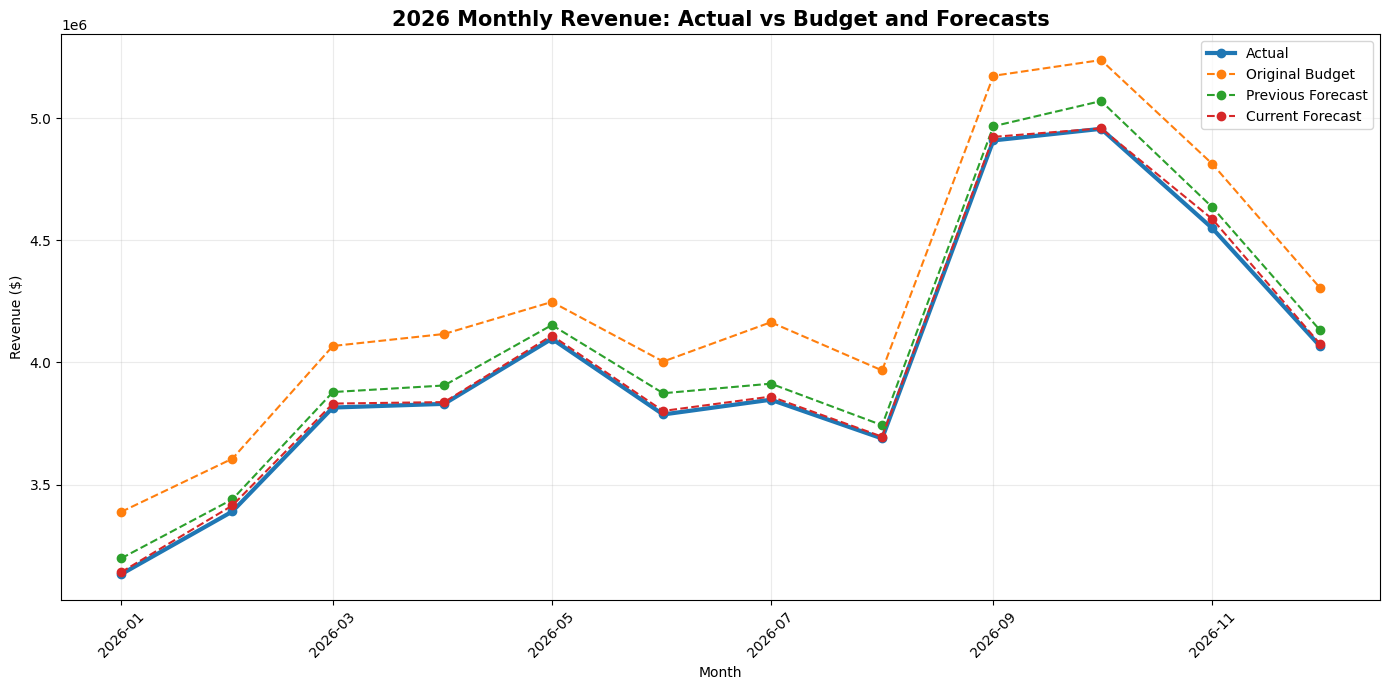

Most accurate planning scenario: Current Forecast
Forecast accuracy: 99.65%


In [16]:
# ---------------------------------------------------------
# Evaluate monthly revenue forecast accuracy
# ---------------------------------------------------------

# Aggregate results to company-month level
company_monthly_financials = (
    monthly_financials
    .groupby(
        ["year_month", "year", "scenario"],
        as_index=False
    )
    .agg(
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum"),
        opex=("opex", "sum"),
        ebitda=("ebitda", "sum")
    )
)

# Convert scenarios into separate columns
revenue_comparison = (
    company_monthly_financials
    .pivot(
        index=["year_month", "year"],
        columns="scenario",
        values="revenue"
    )
    .reset_index()
)

revenue_comparison.columns.name = None

# Restrict the management evaluation to 2026
forecast_evaluation_2026 = revenue_comparison[
    revenue_comparison["year"] == 2026
].copy()

forecast_scenarios = [
    "Original Budget",
    "Previous Forecast",
    "Current Forecast"
]

accuracy_results = []

for scenario_name in forecast_scenarios:

    evaluation = forecast_evaluation_2026[
        ["year_month", "Actual", scenario_name]
    ].dropna()

    actual = evaluation["Actual"]
    predicted = evaluation[scenario_name]

    error = predicted - actual
    absolute_error = error.abs()
    percentage_error = absolute_error / actual.replace(0, np.nan)

    mae = absolute_error.mean()
    rmse = np.sqrt((error ** 2).mean())
    mape = percentage_error.mean()
    wape = absolute_error.sum() / actual.abs().sum()
    bias = error.mean()
    forecast_accuracy = 1 - wape

    accuracy_results.append(
        {
            "scenario": scenario_name,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape,
            "WAPE": wape,
            "forecast_accuracy": forecast_accuracy,
            "forecast_bias": bias
        }
    )

forecast_accuracy_summary = pd.DataFrame(accuracy_results)

# Rank forecasts from most to least accurate
forecast_accuracy_summary["accuracy_rank"] = (
    forecast_accuracy_summary["WAPE"]
    .rank(method="dense")
    .astype(int)
)

forecast_accuracy_summary = (
    forecast_accuracy_summary
    .sort_values("accuracy_rank")
    .reset_index(drop=True)
)

display(
    forecast_accuracy_summary.style
    .format(
        {
            "MAE": "${:,.0f}",
            "RMSE": "${:,.0f}",
            "MAPE": "{:.2%}",
            "WAPE": "{:.2%}",
            "forecast_accuracy": "{:.2%}",
            "forecast_bias": "${:,.0f}"
        }
    )
    .background_gradient(
        subset=["forecast_accuracy"],
        cmap="RdYlGn"
    )
)

# Plot actual revenue against the planning scenarios
plot_data = forecast_evaluation_2026.copy()
plot_data["year_month"] = pd.to_datetime(
    plot_data["year_month"].astype(str)
)

plt.figure(figsize=(14, 7))

plt.plot(
    plot_data["year_month"],
    plot_data["Actual"],
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    plot_data["year_month"],
    plot_data["Original Budget"],
    marker="o",
    linestyle="--",
    label="Original Budget"
)

plt.plot(
    plot_data["year_month"],
    plot_data["Previous Forecast"],
    marker="o",
    linestyle="--",
    label="Previous Forecast"
)

plt.plot(
    plot_data["year_month"],
    plot_data["Current Forecast"],
    marker="o",
    linestyle="--",
    label="Current Forecast"
)

plt.title(
    "2026 Monthly Revenue: Actual vs Budget and Forecasts",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.grid(alpha=0.25)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

best_forecast = forecast_accuracy_summary.iloc[0]

print(
    f"Most accurate planning scenario: "
    f"{best_forecast['scenario']}"
)

print(
    f"Forecast accuracy: "
    f"{best_forecast['forecast_accuracy']:.2%}"
)

## General Ledger Reconciliation and Exception Monitoring

This reconciliation compares operational sales records with General Ledger postings. It identifies matched transactions, amount mismatches, missing records, duplicate postings and timing differences.

Transactions containing exceptions are flagged for investigation, creating an auditable financial-control process.

In [17]:
# ---------------------------------------------------------
# Create operational and General Ledger records
# ---------------------------------------------------------

reconciliation_rng = np.random.default_rng(42)

# Select up to 3,000 actual 2026 sales transactions
sample_size = min(3000, len(
    fact_sales_actual[
        fact_sales_actual["year"] == 2026
    ]
))

reconciliation_source = (
    fact_sales_actual[
        fact_sales_actual["year"] == 2026
    ]
    .sample(
        n=sample_size,
        random_state=42
    )
    .reset_index(drop=True)
)

# Identify transaction ID column
transaction_id_column = next(
    (
        column for column in [
            "transaction_id",
            "sales_transaction_id",
            "order_id",
            "invoice_id"
        ]
        if column in reconciliation_source.columns
    ),
    None
)

if transaction_id_column is None:
    reconciliation_source["transaction_id"] = [
        f"TXN-{number:06d}"
        for number in range(1, len(reconciliation_source) + 1)
    ]
    transaction_id_column = "transaction_id"

# Identify transaction date column
date_column = next(
    (
        column for column in [
            "transaction_date",
            "sales_date",
            "invoice_date",
            "date"
        ]
        if column in reconciliation_source.columns
    ),
    None
)

if date_column is not None:
    operational_dates = pd.to_datetime(
        reconciliation_source[date_column]
    )
else:
    # Construct dates from year_month if no daily date exists
    month_start = pd.to_datetime(
        reconciliation_source["year_month"].astype(str)
    )

    operational_dates = month_start + pd.to_timedelta(
        reconciliation_rng.integers(
            0,
            28,
            size=len(reconciliation_source)
        ),
        unit="D"
    )

# Operational sales records
operational_records = pd.DataFrame(
    {
        "reference_id": (
            reconciliation_source[transaction_id_column]
            .astype(str)
        ),
        "operational_date": operational_dates,
        "operational_amount": reconciliation_source[
            "revenue"
        ].round(2),
        "business_unit_id": reconciliation_source[
            "business_unit_id"
        ],
        "region_id": reconciliation_source["region_id"]
    }
)

operational_records["operational_record_id"] = [
    f"OP-{number:06d}"
    for number in range(1, len(operational_records) + 1)
]

# Create the initial General Ledger records
gl_records = operational_records[
    [
        "reference_id",
        "operational_date",
        "operational_amount",
        "business_unit_id",
        "region_id"
    ]
].copy()

gl_records = gl_records.rename(
    columns={
        "operational_date": "posting_date",
        "operational_amount": "gl_amount"
    }
)

# Normal posting dates occur within 0–2 days
gl_records["posting_date"] = (
    gl_records["posting_date"]
    + pd.to_timedelta(
        reconciliation_rng.integers(
            0,
            3,
            size=len(gl_records)
        ),
        unit="D"
    )
)

record_indices = np.arange(len(gl_records))
reconciliation_rng.shuffle(record_indices)

# Inject controlled exceptions
amount_mismatch_indices = record_indices[:45]
timing_difference_indices = record_indices[45:85]
missing_gl_indices = record_indices[85:115]
duplicate_indices = record_indices[115:140]

# Amount mismatches
gl_records.loc[
    amount_mismatch_indices,
    "gl_amount"
] *= reconciliation_rng.uniform(
    0.93,
    1.07,
    size=len(amount_mismatch_indices)
)

# Timing differences greater than three days
gl_records.loc[
    timing_difference_indices,
    "posting_date"
] += pd.to_timedelta(
    reconciliation_rng.integers(
        5,
        16,
        size=len(timing_difference_indices)
    ),
    unit="D"
)

# Duplicate GL postings
duplicate_gl_records = gl_records.loc[
    duplicate_indices
].copy()

duplicate_gl_records["posting_date"] += pd.to_timedelta(
    1,
    unit="D"
)

# Remove selected entries to create missing GL records
gl_records = gl_records.drop(
    index=missing_gl_indices
)

# Add duplicate postings
gl_records = pd.concat(
    [gl_records, duplicate_gl_records],
    ignore_index=True
)

gl_records["gl_record_id"] = [
    f"GL-{number:06d}"
    for number in range(1, len(gl_records) + 1)
]

gl_records["gl_amount"] = gl_records[
    "gl_amount"
].round(2)

# ---------------------------------------------------------
# Reconcile operational records against the GL
# ---------------------------------------------------------

gl_reconciliation_summary = (
    gl_records
    .groupby("reference_id", as_index=False)
    .agg(
        gl_record_count=("gl_record_id", "count"),
        gl_amount=("gl_amount", "sum"),
        earliest_posting_date=("posting_date", "min"),
        latest_posting_date=("posting_date", "max")
    )
)

reconciliation_results = operational_records.merge(
    gl_reconciliation_summary,
    on="reference_id",
    how="outer",
    indicator=True
)

reconciliation_results["amount_difference"] = (
    reconciliation_results["gl_amount"]
    - reconciliation_results["operational_amount"]
)

reconciliation_results["posting_delay_days"] = (
    reconciliation_results["earliest_posting_date"]
    - reconciliation_results["operational_date"]
).dt.days

# Assign reconciliation status in order of control priority
conditions = [
    reconciliation_results["_merge"] == "left_only",
    reconciliation_results["_merge"] == "right_only",
    reconciliation_results["gl_record_count"] > 1,
    reconciliation_results["amount_difference"].abs() > 1.00,
    reconciliation_results["posting_delay_days"].abs() > 3
]

status_labels = [
    "Missing GL Record",
    "Missing Operational Record",
    "Duplicate GL Posting",
    "Amount Mismatch",
    "Timing Difference"
]

reconciliation_results["reconciliation_status"] = np.select(
    conditions,
    status_labels,
    default="Matched"
)

reconciliation_results["investigation_required"] = np.where(
    reconciliation_results["reconciliation_status"] == "Matched",
    "No",
    "Yes"
)

reconciliation_results["exception_priority"] = (
    reconciliation_results["reconciliation_status"]
    .map(
        {
            "Missing GL Record": "High",
            "Missing Operational Record": "High",
            "Duplicate GL Posting": "High",
            "Amount Mismatch": "Medium",
            "Timing Difference": "Low",
            "Matched": "None"
        }
    )
)

# Management exception summary
reconciliation_summary = (
    reconciliation_results
    .groupby(
        [
            "reconciliation_status",
            "investigation_required",
            "exception_priority"
        ],
        as_index=False
    )
    .agg(
        transaction_count=("reference_id", "count"),
        absolute_amount_difference=(
            "amount_difference",
            lambda values: values.abs().sum()
        )
    )
)

reconciliation_summary["transaction_percentage"] = (
    reconciliation_summary["transaction_count"]
    / reconciliation_summary["transaction_count"].sum()
)

display(
    reconciliation_summary
    .sort_values(
        "transaction_count",
        ascending=False
    )
    .style
    .format(
        {
            "absolute_amount_difference": "${:,.2f}",
            "transaction_percentage": "{:.2%}"
        }
    )
    .background_gradient(
        subset=["transaction_count"],
        cmap="YlOrRd"
    )
)

print(
    "Operational records:",
    f"{len(operational_records):,}"
)

print(
    "GL records:",
    f"{len(gl_records):,}"
)

print(
    "Transactions requiring investigation:",
    f"{(reconciliation_results['investigation_required'] == 'Yes').sum():,}"
)

print("\nReconciliation statuses:")
print(
    reconciliation_results[
        "reconciliation_status"
    ].value_counts()
)

,reconciliation_status,investigation_required,exception_priority,transaction_count,absolute_amount_difference,transaction_percentage
2,Matched,No,None,2860,$0.00,95.33%
0,Amount Mismatch,Yes,Medium,45,"$11,179.12",1.50%
4,Timing Difference,Yes,Low,40,$0.00,1.33%
3,Missing GL Record,Yes,High,30,$0.00,1.00%
1,Duplicate GL Posting,Yes,High,25,"$73,805.79",0.83%


Operational records: 3,000
GL records: 2,995
Transactions requiring investigation: 140

Reconciliation statuses:
reconciliation_status
Matched                 2860
Amount Mismatch           45
Timing Difference         40
Missing GL Record         30
Duplicate GL Posting      25
Name: count, dtype: int64


## Management Scenario Analysis

This scenario model evaluates how changes in business assumptions affect projected revenue, gross profit, EBITDA and pretax income.

Management can test alternative assumptions for selling prices, sales volume, input-cost inflation, headcount, marketing expenditure and interest rates. The model provides a transparent connection between operational decisions and financial outcomes.

,scenario,projected_revenue,projected_gross_profit,projected_opex,projected_ebitda,projected_interest_expense,projected_pretax_income,gross_margin,ebitda_margin,ebitda_change_vs_actual,ebitda_change_pct
0,Downside,"$44,733,898","$13,299,044","$11,032,878","$2,266,165","$1,093,591","$1,172,574",29.7%,5.1%,"$-3,754,985",-62.4%
1,Base Case,"$50,502,292","$17,195,039","$11,166,296","$6,028,742","$925,347","$5,103,396",34.0%,11.9%,"$7,592",0.1%
2,Upside,"$53,992,171","$19,408,783","$11,294,269","$8,114,514","$757,102","$7,357,412",35.9%,15.0%,"$2,093,364",34.8%


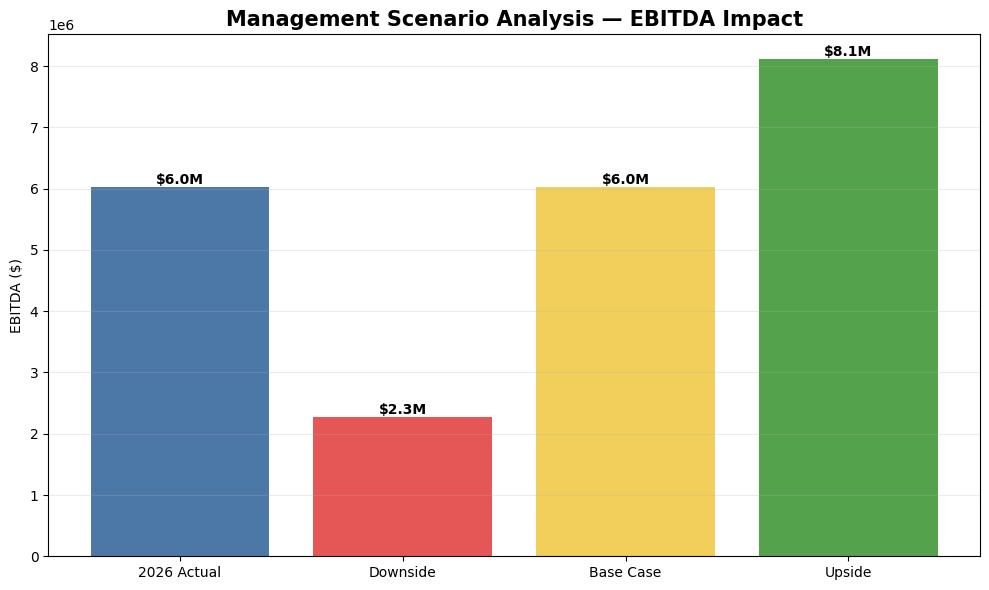

In [18]:
# ---------------------------------------------------------
# Management scenario-analysis model
# ---------------------------------------------------------

# Establish 2026 actual financial baseline
actual_2026_baseline = (
    company_monthly_financials[
        (company_monthly_financials["year"] == 2026)
        & (company_monthly_financials["scenario"] == "Actual")
    ]
    .agg(
        {
            "revenue": "sum",
            "gross_profit": "sum",
            "opex": "sum",
            "ebitda": "sum"
        }
    )
)

base_revenue = actual_2026_baseline["revenue"]
base_gross_profit = actual_2026_baseline["gross_profit"]
base_opex = actual_2026_baseline["opex"]
base_ebitda = actual_2026_baseline["ebitda"]
base_cogs = base_revenue - base_gross_profit

# Simplified management cost assumptions
labor_share_of_opex = 0.45
marketing_share_of_opex = 0.10
other_opex_share = 0.45

base_labor_cost = base_opex * labor_share_of_opex
base_marketing_cost = base_opex * marketing_share_of_opex
base_other_opex = base_opex * other_opex_share

# Illustrative outstanding debt used for interest-rate scenarios
debt_balance = base_revenue * 0.35


def run_financial_scenario(
    scenario_name,
    price_change=0.00,
    volume_change=0.00,
    cogs_inflation=0.00,
    headcount_change=0.00,
    marketing_change=0.00,
    other_opex_inflation=0.00,
    interest_rate=0.055
):
    """
    Calculate projected financial results from management assumptions.
    All change inputs should be entered as decimals.
    Example: 0.05 represents a 5% increase.
    """

    projected_revenue = (
        base_revenue
        * (1 + price_change)
        * (1 + volume_change)
    )

    # Product costs change with volume and input-cost inflation
    projected_cogs = (
        base_cogs
        * (1 + volume_change)
        * (1 + cogs_inflation)
    )

    projected_gross_profit = (
        projected_revenue
        - projected_cogs
    )

    projected_labor_cost = (
        base_labor_cost
        * (1 + headcount_change)
    )

    projected_marketing_cost = (
        base_marketing_cost
        * (1 + marketing_change)
    )

    projected_other_opex = (
        base_other_opex
        * (1 + other_opex_inflation)
    )

    projected_opex = (
        projected_labor_cost
        + projected_marketing_cost
        + projected_other_opex
    )

    projected_ebitda = (
        projected_gross_profit
        - projected_opex
    )

    projected_interest_expense = (
        debt_balance * interest_rate
    )

    projected_pretax_income = (
        projected_ebitda
        - projected_interest_expense
    )

    return {
        "scenario": scenario_name,
        "price_change": price_change,
        "volume_change": volume_change,
        "cogs_inflation": cogs_inflation,
        "headcount_change": headcount_change,
        "marketing_change": marketing_change,
        "interest_rate": interest_rate,
        "projected_revenue": projected_revenue,
        "projected_gross_profit": projected_gross_profit,
        "projected_opex": projected_opex,
        "projected_ebitda": projected_ebitda,
        "projected_interest_expense": projected_interest_expense,
        "projected_pretax_income": projected_pretax_income,
        "gross_margin": (
            projected_gross_profit / projected_revenue
        ),
        "ebitda_margin": (
            projected_ebitda / projected_revenue
        )
    }


# Define management scenarios
management_scenarios = pd.DataFrame(
    [
        run_financial_scenario(
            scenario_name="Downside",
            price_change=-0.01,
            volume_change=-0.06,
            cogs_inflation=0.06,
            headcount_change=0.00,
            marketing_change=-0.05,
            other_opex_inflation=0.04,
            interest_rate=0.065
        ),
        run_financial_scenario(
            scenario_name="Base Case",
            price_change=0.02,
            volume_change=0.03,
            cogs_inflation=0.025,
            headcount_change=0.02,
            marketing_change=0.05,
            other_opex_inflation=0.025,
            interest_rate=0.055
        ),
        run_financial_scenario(
            scenario_name="Upside",
            price_change=0.04,
            volume_change=0.08,
            cogs_inflation=0.015,
            headcount_change=0.04,
            marketing_change=0.10,
            other_opex_inflation=0.02,
            interest_rate=0.045
        )
    ]
)

# Compare each scenario with the 2026 actual baseline
management_scenarios["revenue_change_vs_actual"] = (
    management_scenarios["projected_revenue"]
    - base_revenue
)

management_scenarios["ebitda_change_vs_actual"] = (
    management_scenarios["projected_ebitda"]
    - base_ebitda
)

management_scenarios["ebitda_change_pct"] = (
    management_scenarios["ebitda_change_vs_actual"]
    / base_ebitda
)

scenario_display_columns = [
    "scenario",
    "projected_revenue",
    "projected_gross_profit",
    "projected_opex",
    "projected_ebitda",
    "projected_interest_expense",
    "projected_pretax_income",
    "gross_margin",
    "ebitda_margin",
    "ebitda_change_vs_actual",
    "ebitda_change_pct"
]

currency_columns = [
    "projected_revenue",
    "projected_gross_profit",
    "projected_opex",
    "projected_ebitda",
    "projected_interest_expense",
    "projected_pretax_income",
    "ebitda_change_vs_actual"
]

display(
    management_scenarios[
        scenario_display_columns
    ]
    .style
    .format(
        {
            **{
                column: "${:,.0f}"
                for column in currency_columns
            },
            "gross_margin": "{:.1%}",
            "ebitda_margin": "{:.1%}",
            "ebitda_change_pct": "{:.1%}"
        }
    )
    .background_gradient(
        subset=[
            "projected_ebitda",
            "projected_pretax_income",
            "ebitda_change_vs_actual"
        ],
        cmap="RdYlGn"
    )
)

# Visualize EBITDA across scenarios
scenario_chart = pd.concat(
    [
        pd.DataFrame(
            {
                "scenario": ["2026 Actual"],
                "EBITDA": [base_ebitda]
            }
        ),
        management_scenarios[
            ["scenario", "projected_ebitda"]
        ].rename(
            columns={"projected_ebitda": "EBITDA"}
        )
    ],
    ignore_index=True
)

plt.figure(figsize=(10, 6))

colors = [
    "#4C78A8",
    "#E45756",
    "#F2CF5B",
    "#54A24B"
]

bars = plt.bar(
    scenario_chart["scenario"],
    scenario_chart["EBITDA"],
    color=colors
)

plt.title(
    "Management Scenario Analysis — EBITDA Impact",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("EBITDA ($)")
plt.grid(axis="y", alpha=0.25)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"${bar.get_height() / 1_000_000:.1f}M",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## Data Export for Excel, SQL and Power BI

The analytical tables are exported as structured CSV files. The export includes dimension tables, transaction-level facts, financial statements, variance analysis, forecast accuracy, reconciliation results and scenario-analysis outputs.

These files form the reporting layer for Excel, SQL and Power BI.

In [25]:
# ---------------------------------------------------------
# Export analysis tables as Power BI-ready CSV files
# ---------------------------------------------------------

import os
import shutil
from google.colab import files

export_folder = "fpa_analytics_exports"

# Recreate the export folder
if os.path.exists(export_folder):
    shutil.rmtree(export_folder)

os.makedirs(export_folder, exist_ok=True)

# Organize project datasets
export_tables = {
    # Dimension tables
    "dim_date": dim_date,
    "dim_business_unit": dim_business_unit,
    "dim_region": dim_region,
    "dim_customer_segment": dim_customer_segment,
    "dim_department": dim_department,
    "dim_scenario": dim_scenario,
    "dim_product": dim_product,
    "dim_customer": dim_customer,
    "dim_account": dim_account,

    # External economic data
    "macro_data_hybrid": macro_data_hybrid,

    # Financial fact tables
    "fact_sales_actual": fact_sales_actual,
    "fact_sales_monthly": fact_sales_monthly,
    "fact_opex": fact_opex,
    "monthly_financials": monthly_financials,
    "fact_financial_variance": fact_financial_variance,

    # Analytical outputs
    "pvm_analysis": pvm_analysis,
    "pvm_summary": pvm_summary,
    "forecast_accuracy_summary": forecast_accuracy_summary,
    "management_scenarios": management_scenarios,

    # Reconciliation and control tables
    "operational_records": operational_records,
    "gl_records": gl_records,
    "reconciliation_results": reconciliation_results,
    "reconciliation_summary": reconciliation_summary
}

export_log = []

for table_name, dataframe in export_tables.items():

    export_dataframe = dataframe.copy()

    # Convert period columns into Power BI-compatible text
    for column in export_dataframe.columns:
        if isinstance(
            export_dataframe[column].dtype,
            pd.PeriodDtype
        ):
            export_dataframe[column] = (
                export_dataframe[column].astype(str)
            )

    # Convert timezone-aware dates when necessary
    for column in export_dataframe.select_dtypes(
        include=["datetimetz"]
    ).columns:
        export_dataframe[column] = (
            export_dataframe[column]
            .dt.tz_localize(None)
        )

    file_path = os.path.join(
        export_folder,
        f"{table_name}.csv"
    )

    export_dataframe.to_csv(
        file_path,
        index=False
    )

    export_log.append(
        {
            "table_name": table_name,
            "row_count": len(export_dataframe),
            "column_count": len(export_dataframe.columns),
            "file_name": f"{table_name}.csv"
        }
    )

export_manifest = pd.DataFrame(export_log)

# Export a manifest describing the files
export_manifest.to_csv(
    os.path.join(
        export_folder,
        "export_manifest.csv"
    ),
    index=False
)

# Add a short README file
readme_text = """
Financial Planning, Forecasting & Variance Analytics
Summit Industrial Products, Inc.

This export contains:

1. Dimension tables
2. Transaction-level sales data
3. Monthly Budget, Forecast and Actual results
4. Operating-expense records
5. Monthly financial statements
6. Budget-versus-Actual variance analysis
7. Price-Volume-Mix analysis
8. Forecast-accuracy measurements
9. General Ledger reconciliation results
10. Management scenario-analysis outputs

The files are structured for loading into Excel, SQL or Power BI.
"""

with open(
    os.path.join(export_folder, "README.txt"),
    "w",
    encoding="utf-8"
) as readme_file:
    readme_file.write(readme_text.strip())

# Create ZIP archive
zip_file_path = shutil.make_archive(
    "fpa_analytics_exports",
    "zip",
    export_folder
)

display(export_manifest)

print(
    f"\nExport completed: "
    f"{len(export_manifest)} analytical tables"
)

print(
    f"ZIP file created: {zip_file_path}"
)

# Download the ZIP file
files.download(zip_file_path)

,table_name,row_count,column_count,file_name
0,dim_date,1096,8,dim_date.csv
1,dim_business_unit,4,4,dim_business_unit.csv
2,dim_region,4,3,dim_region.csv
3,dim_customer_segment,3,4,dim_customer_segment.csv
4,dim_department,6,2,dim_department.csv
5,dim_scenario,4,3,dim_scenario.csv
6,dim_product,12,8,dim_product.csv
7,dim_customer,240,8,dim_customer.csv
8,dim_account,18,5,dim_account.csv
9,macro_data_hybrid,36,32,macro_data_hybrid.csv



Export completed: 23 analytical tables
ZIP file created: /content/fpa_analytics_exports.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## SQL Analytics Layer

The project tables are loaded into a relational SQL database. Reusable analytical views provide monthly financial performance, Budget-versus-Actual comparisons, exception monitoring and product-level revenue analysis.

This demonstrates how SQL can support a governed reporting layer before the results are delivered through Excel and Power BI.

In [24]:
# ---------------------------------------------------------
# Step 20: Create SQLite FP&A analytics database
# ---------------------------------------------------------

import os
import sqlite3
import zipfile
import pandas as pd
from google.colab import files

database_file = "fpa_analytics_database.db"
sql_script_file = "fpa_management_queries.sql"
sql_zip_file = "fpa_sql_analytics_layer.zip"

# Remove incomplete files from previous attempts
for file_name in [
    database_file,
    sql_script_file,
    sql_zip_file
]:
    if os.path.exists(file_name):
        os.remove(file_name)

# Open a new SQLite database connection
connection = sqlite3.connect(database_file)

# ---------------------------------------------------------
# Define tables to load into SQL
# ---------------------------------------------------------

sql_tables = {
    "dim_date": dim_date,
    "dim_business_unit": dim_business_unit,
    "dim_region": dim_region,
    "dim_customer_segment": dim_customer_segment,
    "dim_department": dim_department,
    "dim_scenario": dim_scenario,
    "dim_product": dim_product,
    "dim_customer": dim_customer,
    "dim_account": dim_account,
    "macro_data": macro_data_hybrid,
    "fact_sales_actual": fact_sales_actual,
    "fact_sales_monthly": fact_sales_monthly,
    "fact_opex": fact_opex,
    "monthly_financials": monthly_financials,
    "fact_financial_variance": fact_financial_variance,
    "operational_records": operational_records,
    "gl_records": gl_records,
    "reconciliation_results": reconciliation_results
}

sql_load_log = []

# ---------------------------------------------------------
# Load pandas DataFrames into SQLite
# ---------------------------------------------------------

for table_name, dataframe in sql_tables.items():

    sql_dataframe = dataframe.copy()

    # Convert pandas Period columns to text
    for column in sql_dataframe.columns:
        if isinstance(
            sql_dataframe[column].dtype,
            pd.PeriodDtype
        ):
            sql_dataframe[column] = (
                sql_dataframe[column].astype(str)
            )

    # Convert datetime columns to SQL-compatible text
    datetime_columns = sql_dataframe.select_dtypes(
        include=["datetime", "datetimetz"]
    ).columns

    for column in datetime_columns:
        sql_dataframe[column] = (
            pd.to_datetime(
                sql_dataframe[column],
                errors="coerce"
            )
            .dt.strftime("%Y-%m-%d")
        )

    sql_dataframe.to_sql(
        table_name,
        connection,
        if_exists="replace",
        index=False
    )

    sql_load_log.append(
        {
            "table_name": table_name,
            "rows_loaded": len(sql_dataframe),
            "columns_loaded": len(sql_dataframe.columns)
        }
    )

# ---------------------------------------------------------
# Create reusable SQL management views
# ---------------------------------------------------------

management_sql = """
-- ========================================================
-- FP&A MANAGEMENT REPORTING VIEWS
-- Summit Industrial Products, Inc.
-- ========================================================


-- --------------------------------------------------------
-- View 1: Monthly financial performance
-- --------------------------------------------------------

DROP VIEW IF EXISTS vw_monthly_financial_performance;

CREATE VIEW vw_monthly_financial_performance AS
SELECT
    mf.year_month,
    mf.year,
    mf.business_unit_id,
    bu.business_unit_name,
    mf.region_id,
    r.region_name,
    mf.scenario,
    mf.revenue,
    mf.gross_profit,
    mf.opex,
    mf.operating_income,
    mf.ebitda,

    CASE
        WHEN mf.revenue <> 0
        THEN mf.gross_profit / mf.revenue
        ELSE NULL
    END AS gross_margin,

    CASE
        WHEN mf.revenue <> 0
        THEN mf.operating_income / mf.revenue
        ELSE NULL
    END AS operating_margin,

    CASE
        WHEN mf.revenue <> 0
        THEN mf.ebitda / mf.revenue
        ELSE NULL
    END AS ebitda_margin

FROM monthly_financials AS mf

LEFT JOIN dim_business_unit AS bu
    ON mf.business_unit_id = bu.business_unit_id

LEFT JOIN dim_region AS r
    ON mf.region_id = r.region_id;


-- --------------------------------------------------------
-- View 2: Budget-versus-Actual financial variance
-- --------------------------------------------------------

DROP VIEW IF EXISTS vw_budget_vs_actual;

CREATE VIEW vw_budget_vs_actual AS
SELECT
    fv.year_month,
    fv.year,
    fv.business_unit_id,
    bu.business_unit_name,
    fv.region_id,
    r.region_name,
    fv.benchmark_scenario,

    fv.actual_revenue,
    fv.benchmark_revenue,
    fv.revenue_variance,
    fv.revenue_variance_pct,

    fv.actual_gross_profit,
    fv.benchmark_gross_profit,
    fv.gross_profit_variance,
    fv.gross_profit_variance_pct,

    fv.actual_opex,
    fv.benchmark_opex,
    fv.opex_favorable_variance,
    fv.opex_variance_pct,

    fv.actual_operating_income,
    fv.benchmark_operating_income,
    fv.operating_income_variance,

    fv.actual_ebitda,
    fv.benchmark_ebitda,
    fv.ebitda_variance,
    fv.ebitda_variance_pct,

    fv.revenue_status,
    fv.opex_status,
    fv.ebitda_status

FROM fact_financial_variance AS fv

LEFT JOIN dim_business_unit AS bu
    ON fv.business_unit_id = bu.business_unit_id

LEFT JOIN dim_region AS r
    ON fv.region_id = r.region_id;


-- --------------------------------------------------------
-- View 3: Reconciliation exceptions
-- --------------------------------------------------------

DROP VIEW IF EXISTS vw_reconciliation_exceptions;

CREATE VIEW vw_reconciliation_exceptions AS
SELECT
    reference_id,
    operational_record_id,
    operational_date,
    operational_amount,
    gl_record_count,
    gl_amount,
    amount_difference,
    earliest_posting_date,
    latest_posting_date,
    posting_delay_days,
    reconciliation_status,
    investigation_required,
    exception_priority

FROM reconciliation_results

WHERE investigation_required = 'Yes';


-- --------------------------------------------------------
-- View 4: Product sales performance
-- --------------------------------------------------------

DROP VIEW IF EXISTS vw_product_sales_performance;

CREATE VIEW vw_product_sales_performance AS
SELECT
    s.year,
    s.year_month,
    s.product_id,
    p.product_name,
    s.business_unit_id,
    bu.business_unit_name,
    s.region_id,
    r.region_name,

    SUM(s.units) AS total_units,
    SUM(s.revenue) AS total_revenue,
    SUM(s.cogs) AS total_cogs,
    SUM(s.gross_profit) AS total_gross_profit,

    CASE
        WHEN SUM(s.revenue) <> 0
        THEN SUM(s.gross_profit) / SUM(s.revenue)
        ELSE NULL
    END AS gross_margin

FROM fact_sales_actual AS s

LEFT JOIN dim_product AS p
    ON s.product_id = p.product_id

LEFT JOIN dim_business_unit AS bu
    ON s.business_unit_id = bu.business_unit_id

LEFT JOIN dim_region AS r
    ON s.region_id = r.region_id

GROUP BY
    s.year,
    s.year_month,
    s.product_id,
    p.product_name,
    s.business_unit_id,
    bu.business_unit_name,
    s.region_id,
    r.region_name;


-- --------------------------------------------------------
-- View 5: Annual executive performance
-- --------------------------------------------------------

DROP VIEW IF EXISTS vw_annual_executive_performance;

CREATE VIEW vw_annual_executive_performance AS
SELECT
    year,
    scenario,

    SUM(revenue) AS total_revenue,
    SUM(gross_profit) AS total_gross_profit,
    SUM(opex) AS total_opex,
    SUM(operating_income) AS total_operating_income,
    SUM(ebitda) AS total_ebitda,

    CASE
        WHEN SUM(revenue) <> 0
        THEN SUM(gross_profit) / SUM(revenue)
        ELSE NULL
    END AS gross_margin,

    CASE
        WHEN SUM(revenue) <> 0
        THEN SUM(ebitda) / SUM(revenue)
        ELSE NULL
    END AS ebitda_margin

FROM monthly_financials

GROUP BY
    year,
    scenario;


-- --------------------------------------------------------
-- View 6: Exception summary
-- --------------------------------------------------------

DROP VIEW IF EXISTS vw_exception_summary;

CREATE VIEW vw_exception_summary AS
SELECT
    reconciliation_status,
    exception_priority,
    investigation_required,
    COUNT(*) AS transaction_count,
    SUM(ABS(COALESCE(amount_difference, 0)))
        AS absolute_amount_difference

FROM reconciliation_results

GROUP BY
    reconciliation_status,
    exception_priority,
    investigation_required;
"""

# Execute the complete SQL script
connection.executescript(management_sql)
connection.commit()

# Save SQL script as a separate portfolio file
with open(
    sql_script_file,
    "w",
    encoding="utf-8"
) as sql_file:
    sql_file.write(management_sql.strip())

# ---------------------------------------------------------
# Validate SQL tables and views
# ---------------------------------------------------------

sql_load_summary = pd.DataFrame(sql_load_log)

validation_queries = {
    "Monthly financial performance": """
        SELECT COUNT(*)
        FROM vw_monthly_financial_performance
    """,

    "Budget-versus-Actual analysis": """
        SELECT COUNT(*)
        FROM vw_budget_vs_actual
    """,

    "Reconciliation exceptions": """
        SELECT COUNT(*)
        FROM vw_reconciliation_exceptions
    """,

    "Product sales performance": """
        SELECT COUNT(*)
        FROM vw_product_sales_performance
    """,

    "Annual executive performance": """
        SELECT COUNT(*)
        FROM vw_annual_executive_performance
    """,

    "Exception summary": """
        SELECT COUNT(*)
        FROM vw_exception_summary
    """
}

validation_results = []

for sql_object, query in validation_queries.items():

    result = pd.read_sql_query(
        query,
        connection
    )

    validation_results.append(
        {
            "sql_object": sql_object,
            "record_count": result.iloc[0, 0],
            "validation_status": "Passed"
        }
    )

sql_validation_summary = pd.DataFrame(
    validation_results
)

print("SQL tables loaded successfully:")
display(sql_load_summary)

print("\nSQL views validated successfully:")
display(sql_validation_summary)

# ---------------------------------------------------------
# Run executive management query
# ---------------------------------------------------------

executive_sql_query = """
SELECT
    benchmark_scenario,

    ROUND(
        SUM(actual_revenue),
        2
    ) AS actual_revenue,

    ROUND(
        SUM(benchmark_revenue),
        2
    ) AS benchmark_revenue,

    ROUND(
        SUM(revenue_variance),
        2
    ) AS revenue_variance,

    ROUND(
        100.0 * SUM(revenue_variance)
        / NULLIF(SUM(benchmark_revenue), 0),
        2
    ) AS revenue_variance_pct,

    ROUND(
        SUM(actual_ebitda),
        2
    ) AS actual_ebitda,

    ROUND(
        SUM(benchmark_ebitda),
        2
    ) AS benchmark_ebitda,

    ROUND(
        SUM(ebitda_variance),
        2
    ) AS ebitda_variance,

    ROUND(
        100.0 * SUM(ebitda_variance)
        / NULLIF(SUM(benchmark_ebitda), 0),
        2
    ) AS ebitda_variance_pct

FROM vw_budget_vs_actual

WHERE year = 2026

GROUP BY benchmark_scenario

ORDER BY
    CASE benchmark_scenario
        WHEN 'Original Budget' THEN 1
        WHEN 'Previous Forecast' THEN 2
        WHEN 'Current Forecast' THEN 3
        ELSE 4
    END;
"""

executive_sql_result = pd.read_sql_query(
    executive_sql_query,
    connection
)

print("\n2026 executive Budget-versus-Actual results:")
display(executive_sql_result)

# ---------------------------------------------------------
# Show reconciliation exceptions by category
# ---------------------------------------------------------

exception_sql_result = pd.read_sql_query(
    """
    SELECT
        reconciliation_status,
        exception_priority,
        transaction_count,
        ROUND(
            absolute_amount_difference,
            2
        ) AS absolute_amount_difference
    FROM vw_exception_summary
    ORDER BY
        CASE exception_priority
            WHEN 'High' THEN 1
            WHEN 'Medium' THEN 2
            WHEN 'Low' THEN 3
            ELSE 4
        END,
        transaction_count DESC;
    """,
    connection
)

print("\nReconciliation control summary:")
display(exception_sql_result)

# Close the database connection
connection.close()

# ---------------------------------------------------------
# Package SQL deliverables
# ---------------------------------------------------------

with zipfile.ZipFile(
    sql_zip_file,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    zip_file.write(
        database_file,
        arcname=database_file
    )

    zip_file.write(
        sql_script_file,
        arcname=sql_script_file
    )

print("\nStep 20 completed successfully.")
print(f"Database created: {database_file}")
print(f"SQL script created: {sql_script_file}")
print(f"Download package created: {sql_zip_file}")

# Download SQL package
files.download(sql_zip_file)

SQL tables loaded successfully:


,table_name,rows_loaded,columns_loaded
0,dim_date,1096,8
1,dim_business_unit,4,4
2,dim_region,4,3
3,dim_customer_segment,3,4
4,dim_department,6,2
5,dim_scenario,4,3
6,dim_product,12,8
7,dim_customer,240,8
8,dim_account,18,5
9,macro_data,36,32



SQL views validated successfully:


,sql_object,record_count,validation_status
0,Monthly financial performance,2304,Passed
1,Budget-versus-Actual analysis,1728,Passed
2,Reconciliation exceptions,140,Passed
3,Product sales performance,1727,Passed
4,Annual executive performance,12,Passed
5,Exception summary,5,Passed



2026 executive Budget-versus-Actual results:


...


Reconciliation control summary:


,reconciliation_status,exception_priority,transaction_count,absolute_amount_difference
0,Missing GL Record,High,30,0.00
1,Duplicate GL Posting,High,25,"73,805.79"
2,Amount Mismatch,Medium,45,"11,179.12"
3,Timing Difference,Low,40,0.00
4,Matched,None,2860,0.00



Step 20 completed successfully.
Database created: fpa_analytics_database.db
SQL script created: fpa_management_queries.sql
Download package created: fpa_sql_analytics_layer.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Excel Management Reporting Workbook

A formatted Excel workbook consolidates the project’s financial statements, analytical outputs and supporting records. It provides a familiar management-reporting deliverable that can also serve as a controlled source for Power BI.

In [30]:
# ---------------------------------------------------------
# Step 21: Create professional Excel FP&A workbook
# ---------------------------------------------------------

import os
import numpy as np
import pandas as pd
from google.colab import files

excel_file = "Summit_Industrial_FP&A_Analytics.xlsx"

if os.path.exists(excel_file):
    os.remove(excel_file)

# ---------------------------------------------------------
# Prepare executive-summary data
# ---------------------------------------------------------

annual_performance = (
    company_monthly_financials
    .groupby(
        ["year", "scenario"],
        as_index=False
    )
    .agg(
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum"),
        opex=("opex", "sum"),
        ebitda=("ebitda", "sum")
    )
)

annual_performance["gross_margin"] = (
    annual_performance["gross_profit"]
    / annual_performance["revenue"]
)

annual_performance["ebitda_margin"] = (
    annual_performance["ebitda"]
    / annual_performance["revenue"]
)

executive_summary_2026 = annual_performance[
    annual_performance["year"] == 2026
].copy()

scenario_order = {
    "Original Budget": 1,
    "Previous Forecast": 2,
    "Current Forecast": 3,
    "Actual": 4
}

executive_summary_2026["scenario_order"] = (
    executive_summary_2026["scenario"]
    .map(scenario_order)
)

executive_summary_2026 = (
    executive_summary_2026
    .sort_values("scenario_order")
    .drop(columns="scenario_order")
    .reset_index(drop=True)
)

# Reconciliation summary for Excel
excel_reconciliation_summary = (
    reconciliation_results
    .groupby(
        [
            "reconciliation_status",
            "exception_priority",
            "investigation_required"
        ],
        as_index=False
    )
    .agg(
        transaction_count=("reference_id", "count"),
        absolute_amount_difference=(
            "amount_difference",
            lambda values: values.abs().sum()
        )
    )
)

excel_reconciliation_summary[
    "transaction_percentage"
] = (
    excel_reconciliation_summary["transaction_count"]
    / excel_reconciliation_summary["transaction_count"].sum()
)

# ---------------------------------------------------------
# Define workbook sheets
# ---------------------------------------------------------

excel_tables = {
    "Annual Performance": annual_performance,
    "Monthly Financials": monthly_financials,
    "Variance Analysis": fact_financial_variance,
    "PVM Analysis": pvm_analysis,
    "PVM Summary": pvm_summary,
    "Forecast Accuracy": forecast_accuracy_summary,
    "Scenario Analysis": management_scenarios,
    "Reconciliation Summary": excel_reconciliation_summary,
    "Reconciliation Detail": reconciliation_results,
    "Sales Transactions": fact_sales_actual,
    "OPEX Detail": fact_opex,
    "Economic Drivers": macro_data_hybrid
}

# ---------------------------------------------------------
# Helper: make Excel-compatible copies
# ---------------------------------------------------------

def prepare_for_excel(dataframe):

    excel_dataframe = dataframe.copy()

    for column in excel_dataframe.columns:

        if isinstance(
            excel_dataframe[column].dtype,
            pd.PeriodDtype
        ):
            excel_dataframe[column] = (
                excel_dataframe[column].astype(str)
            )

        elif isinstance(
            excel_dataframe[column].dtype,
            pd.DatetimeTZDtype
        ):
            excel_dataframe[column] = (
                excel_dataframe[column]
                .dt.tz_localize(None)
            )

    return excel_dataframe


# ---------------------------------------------------------
# Create workbook
# ---------------------------------------------------------

with pd.ExcelWriter(
    excel_file,
    engine="xlsxwriter",
    datetime_format="mmm d, yyyy",
    date_format="mmm d, yyyy"
) as writer:

    workbook = writer.book

    # Workbook color palette
    navy = "#17365D"
    blue = "#4472C4"
    light_blue = "#D9EAF7"
    green = "#70AD47"
    light_green = "#E2F0D9"
    red = "#C00000"
    light_red = "#FCE4D6"
    gold = "#FFC000"
    gray = "#D9E1F2"
    dark_gray = "#595959"
    white = "#FFFFFF"

    # Formats
    title_format = workbook.add_format(
        {
            "bold": True,
            "font_size": 20,
            "font_color": white,
            "bg_color": navy,
            "align": "left",
            "valign": "vcenter"
        }
    )

    subtitle_format = workbook.add_format(
        {
            "italic": True,
            "font_size": 11,
            "font_color": dark_gray
        }
    )

    section_format = workbook.add_format(
        {
            "bold": True,
            "font_size": 12,
            "font_color": white,
            "bg_color": blue,
            "border": 1
        }
    )

    header_format = workbook.add_format(
        {
            "bold": True,
            "font_color": white,
            "bg_color": navy,
            "border": 1,
            "align": "center",
            "valign": "vcenter",
            "text_wrap": True
        }
    )

    currency_format = workbook.add_format(
        {
            "num_format": '$#,##0;[Red]-$#,##0',
            "border": 1
        }
    )

    percentage_format = workbook.add_format(
        {
            "num_format": "0.0%;[Red]-0.0%",
            "border": 1
        }
    )

    number_format = workbook.add_format(
        {
            "num_format": "#,##0",
            "border": 1
        }
    )

    decimal_format = workbook.add_format(
        {
            "num_format": "#,##0.00",
            "border": 1
        }
    )

    text_format = workbook.add_format(
        {
            "border": 1
        }
    )

    favorable_format = workbook.add_format(
        {
            "bg_color": light_green,
            "font_color": "#375623"
        }
    )

    unfavorable_format = workbook.add_format(
        {
            "bg_color": light_red,
            "font_color": red
        }
    )

    kpi_label_format = workbook.add_format(
        {
            "bold": True,
            "font_color": white,
            "bg_color": blue,
            "border": 1,
            "align": "center"
        }
    )

    kpi_value_format = workbook.add_format(
        {
            "bold": True,
            "font_size": 14,
            "num_format": '$#,##0,,"M"',
            "bg_color": light_blue,
            "border": 1,
            "align": "center"
        }
    )

    # -----------------------------------------------------
    # Executive Summary sheet
    # -----------------------------------------------------

    executive_summary_2026.to_excel(
        writer,
        sheet_name="Executive Summary",
        startrow=8,
        startcol=0,
        index=False
    )

    dashboard = writer.sheets["Executive Summary"]

    dashboard.hide_gridlines(2)
    dashboard.set_zoom(90)
    dashboard.set_column("A:A", 20)
    dashboard.set_column("B:E", 18)
    dashboard.set_column("F:G", 16)
    dashboard.set_column("I:P", 14)

    dashboard.merge_range(
        "A1:P2",
        "Financial Planning, Forecasting & Variance Analytics",
        title_format
    )

    dashboard.write(
        "A3",
        "Summit Industrial Products, Inc. | Executive Management Report",
        subtitle_format
    )

    actual_2026 = executive_summary_2026[
        executive_summary_2026["scenario"] == "Actual"
    ].iloc[0]

    dashboard.write("A5", "Actual Revenue", kpi_label_format)
    dashboard.write("B5", actual_2026["revenue"], kpi_value_format)

    dashboard.write("C5", "Gross Profit", kpi_label_format)
    dashboard.write("D5", actual_2026["gross_profit"], kpi_value_format)

    dashboard.write("E5", "Operating Expenses", kpi_label_format)
    dashboard.write("F5", actual_2026["opex"], kpi_value_format)

    dashboard.write("G5", "EBITDA", kpi_label_format)
    dashboard.write("H5", actual_2026["ebitda"], kpi_value_format)

    dashboard.write(
        "A8",
        "2026 Budget, Forecast and Actual Performance",
        section_format
    )

    # Format executive summary headers
    for column_number, column_name in enumerate(
        executive_summary_2026.columns
    ):
        dashboard.write(
            8,
            column_number,
            column_name.replace("_", " ").title(),
            header_format
        )

    # Apply number formats
    executive_columns = list(executive_summary_2026.columns)

    for column_name in [
        "revenue",
        "gross_profit",
        "opex",
        "ebitda"
    ]:
        column_number = executive_columns.index(column_name)

        dashboard.set_column(
            column_number,
            column_number,
            18,
            currency_format
        )

    for column_name in [
        "gross_margin",
        "ebitda_margin"
    ]:
        column_number = executive_columns.index(column_name)

        dashboard.set_column(
            column_number,
            column_number,
            15,
            percentage_format
        )

    # Executive performance chart
    scenario_chart = workbook.add_chart(
        {"type": "column"}
    )

    revenue_column = (
        executive_columns.index("revenue")
    )

    ebitda_column = (
        executive_columns.index("ebitda")
    )

    scenario_column = (
        executive_columns.index("scenario")
    )

    first_data_row = 9
    last_data_row = (
        first_data_row
        + len(executive_summary_2026)
        - 1
    )

    scenario_chart.add_series(
        {
            "name": "Revenue",
            "categories": [
                "Executive Summary",
                first_data_row,
                scenario_column,
                last_data_row,
                scenario_column
            ],
            "values": [
                "Executive Summary",
                first_data_row,
                revenue_column,
                last_data_row,
                revenue_column
            ],
            "fill": {"color": blue}
        }
    )

    scenario_chart.add_series(
        {
            "name": "EBITDA",
            "categories": [
                "Executive Summary",
                first_data_row,
                scenario_column,
                last_data_row,
                scenario_column
            ],
            "values": [
                "Executive Summary",
                first_data_row,
                ebitda_column,
                last_data_row,
                ebitda_column
            ],
            "fill": {"color": green}
        }
    )

    scenario_chart.set_title(
        {"name": "2026 Financial Performance"}
    )

    scenario_chart.set_y_axis(
        {
            "name": "US Dollars",
            "num_format": '$0,,"M"'
        }
    )

    scenario_chart.set_legend(
        {"position": "bottom"}
    )

    scenario_chart.set_style(10)

    dashboard.insert_chart(
        "I5",
        scenario_chart,
        {
            "x_scale": 1.35,
            "y_scale": 1.25
        }
    )

    # -----------------------------------------------------
    # Write supporting tables
    # -----------------------------------------------------

    for sheet_name, dataframe in excel_tables.items():

        excel_dataframe = prepare_for_excel(dataframe)

        excel_dataframe.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

        worksheet = writer.sheets[sheet_name]

        worksheet.hide_gridlines(2)
        worksheet.freeze_panes(1, 0)
        worksheet.set_zoom(85)

        row_count = len(excel_dataframe)
        column_count = len(excel_dataframe.columns)

        # Format headers
        for column_number, column_name in enumerate(
            excel_dataframe.columns
        ):
            worksheet.write(
                0,
                column_number,
                column_name.replace("_", " ").title(),
                header_format
            )

        # Add filters
        if row_count > 0 and column_count > 0:
            worksheet.autofilter(
                0,
                0,
                row_count,
                column_count - 1
            )

        # Apply formats and practical widths
        for column_number, column_name in enumerate(
            excel_dataframe.columns
        ):

            column_lower = column_name.lower()

            sample_values = (
                excel_dataframe[column_name]
                .astype(str)
                .head(200)
            )

            content_width = max(
                len(column_name) + 2,
                sample_values.map(len).max()
                if len(sample_values) > 0
                else 10
            )

            column_width = min(
                max(content_width, 12),
                28
            )

            if any(
                keyword in column_lower
                for keyword in [
                    "revenue",
                    "amount",
                    "profit",
                    "opex",
                    "cogs",
                    "ebitda",
                    "income",
                    "variance",
                    "price",
                    "cost"
                ]
            ) and "pct" not in column_lower:

                worksheet.set_column(
                    column_number,
                    column_number,
                    column_width,
                    currency_format
                )

            elif any(
                keyword in column_lower
                for keyword in [
                    "margin",
                    "percentage",
                    "_pct",
                    "mape",
                    "wape",
                    "accuracy",
                    "mix",
                    "share",
                    "rate"
                ]
            ):

                worksheet.set_column(
                    column_number,
                    column_number,
                    column_width,
                    percentage_format
                )

            elif any(
                keyword in column_lower
                for keyword in [
                    "units",
                    "count",
                    "year"
                ]
            ):

                worksheet.set_column(
                    column_number,
                    column_number,
                    column_width,
                    number_format
                )

            else:
                worksheet.set_column(
                    column_number,
                    column_number,
                    column_width,
                    text_format
                )

        # Favorable and unfavorable status formatting
        status_columns = [
            index
            for index, column in enumerate(
                excel_dataframe.columns
            )
            if "status" in column.lower()
        ]

        for status_column in status_columns:

            worksheet.conditional_format(
                1,
                status_column,
                row_count,
                status_column,
                {
                    "type": "text",
                    "criteria": "containing",
                    "value": "Favorable",
                    "format": favorable_format
                }
            )

            worksheet.conditional_format(
                1,
                status_column,
                row_count,
                status_column,
                {
                    "type": "text",
                    "criteria": "containing",
                    "value": "Unfavorable",
                    "format": unfavorable_format
                }
            )

    # -----------------------------------------------------
    # Add data dictionary
    # -----------------------------------------------------

    data_dictionary_records = []

    for sheet_name, dataframe in excel_tables.items():
        for column_name in dataframe.columns:

            data_dictionary_records.append(
                {
                    "worksheet": sheet_name,
                    "field_name": column_name,
                    "data_type": str(
                        dataframe[column_name].dtype
                    ),
                    "description": (
                        column_name
                        .replace("_", " ")
                        .title()
                    )
                }
            )

    data_dictionary = pd.DataFrame(
        data_dictionary_records
    )

    data_dictionary.to_excel(
        writer,
        sheet_name="Data Dictionary",
        index=False
    )

    dictionary_sheet = writer.sheets[
        "Data Dictionary"
    ]

    dictionary_sheet.hide_gridlines(2)
    dictionary_sheet.freeze_panes(1, 0)
    dictionary_sheet.autofilter(
        0,
        0,
        len(data_dictionary),
        len(data_dictionary.columns) - 1
    )

    dictionary_sheet.set_column("A:A", 24)
    dictionary_sheet.set_column("B:B", 30)
    dictionary_sheet.set_column("C:C", 18)
    dictionary_sheet.set_column("D:D", 42)

    for column_number, column_name in enumerate(
        data_dictionary.columns
    ):
        dictionary_sheet.write(
            0,
            column_number,
            column_name.replace("_", " ").title(),
            header_format
        )

print(f"Excel workbook created: {excel_file}")
print(
    f"Workbook sheets created: "
    f"{len(excel_tables) + 2}"
)

files.download(excel_file)

Excel workbook created: Summit_Industrial_FP&A_Analytics.xlsx
Workbook sheets created: 14


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
!pip install -q XlsxWriter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.5 MB/s eta 0:00:00


In [29]:
import xlsxwriter

print("XlsxWriter installed successfully.")
print("Version:", xlsxwriter.__version__)

XlsxWriter installed successfully.
Version: 3.2.9
